# Lunar-HFE: run everything

This notebook reproduces the whole study behind the JGR: Planets letter
*"Difference of the Lunar Regolith Thermal Conductivity $K_d$ at the Apollo 15
and 17 Heat-Flow Boreholes from Global Model Values"* and its Supporting
Information (SI), code release **v2.1.1-jgr**.

**How to use it:** choose `MODE` in the first code cell below, then
**Run All** (JupyterLab: *Run ▸ Run All Cells*; VS Code: *Run All*).

| `MODE` | What runs | Time |
|---|---|---|
| `"show"` (default) | nothing is recomputed: every step reads its stored result in `code/results/` | a few minutes |
| `"quick"` | the short steps run; the long ones run their fast form (re-analysing stored model runs) or show their stored result | about 45 min |
| `"full"` | every step from scratch, as for the paper | about 6 h on a six-core laptop |

**What it contains**

1. **Setup**: checks that the computer is ready; optional downloads.
2. **The analysis**: every step of the study, in the order in which the steps need each other.
3. **The figures**: every figure of the letter and the SI.
4. **The paper, section by section**: each number of the letter next to the value
   this repository gives (✓ / ✗), in the order of the letter: each probe, each
   thermometer type, all the sensors together, why all three measurements are
   needed, the checks, and the discussion.
5. **The Supporting Information, table by table**: every number of the 14 SI
   tables next to the value this repository gives.
6. **Summary**: how many values were checked, and whether all of them match.

Each step is one script in `code/pipeline/`. The cell runs it and shows its
printout as it goes. The notebook computes nothing itself, so it and
`make aux` run exactly the same code. On a Mac every step keeps the computer
awake (`caffeinate`), but not with the lid closed: keep it open during a long run.

Two optional notebooks go deeper: `optional_anchor_method.ipynb` (how the
solver reaches its steady state, step by step) and `optional_performance.ipynb`
(the solver in Python against C++).

In [1]:
# How much to run:  "show"  (minutes) | "quick"  (about 45 min) | "full"  (about 6 h)
MODE = "show"

try:
    from lunar import notebook as nb
except ImportError:
    raise ImportError("The lunar package is not installed. In a terminal, in the repository folder, run:\n"
                      "    pip install -e \".[dev,mcmc]\"\nthen restart the kernel.")
import numpy as np
import pandas as pd
from IPython.display import display
nb.set_mode(MODE)
S2 = ("A15", "A17")
DIVINER = ("data/diviner/gcp/global_cumul_avg_cyl_20n30n_002.tab", "data/diviner/gcp/global_cumul_avg_cyl_10n20n_002.tab")

Run mode: 'show'. Nothing is recomputed; every step shows its stored result.


---
# 1. Setup

## 1.1 Python and the core libraries
Python 3.10 or newer. A version problem is the most common reason a notebook
will not run, so it is checked first.

In [2]:
import sys, platform
print(f"Python {sys.version.split()[0]} on {platform.system()} {platform.machine()}")
assert sys.version_info >= (3, 10), "Python 3.10+ required"
import scipy, matplotlib, numba
for mod in (np, scipy, matplotlib, pd, numba):
    print(f"  {mod.__name__:<12} {mod.__version__}")

Python 3.13.13 on Darwin arm64


  numpy        2.4.6
  scipy        1.18.0
  matplotlib   3.11.1
  pandas       3.0.5
  numba        0.66.0


## 1.2 The `lunar` package and its constants
The physics is the installed package `lunar` (`code/src/lunar/`). This checks
the constants the study is defined by: the Stefan–Boltzmann constant and the
Hayne et al. (2017) regolith parameters.

In [3]:
import math
from lunar import constants as c
assert math.isclose(c.SIGMA_SB, 5.670374419e-8, rel_tol=1e-6), "SIGMA_SB constant wrong"
assert math.isclose(c.K_DEEP, 3.4e-3, rel_tol=1e-6), "Hayne K_d default is wrong"
assert math.isclose(c.K_SURFACE, 7.4e-4, rel_tol=1e-6), "Hayne K_s default is wrong"
assert math.isclose(c.H_PARAMETER, 0.06, rel_tol=1e-6), "Hayne H is wrong"
print(f"  sigma = {c.SIGMA_SB} W m^-2 K^-4")
print(f"  Hayne global K_d = {c.K_DEEP*1e3:.1f} mW m^-1 K^-1,  K_s = {c.K_SURFACE*1e3:.2f},  H = {c.H_PARAMETER*100:.0f} cm")

  sigma = 5.670374419e-08 W m^-2 K^-4
  Hayne global K_d = 3.4 mW m^-1 K^-1,  K_s = 0.74,  H = 6 cm


## 1.3 The Apollo heat-flow record
The 1971–1977 record (St. Clair et al., 2020; Nagihara et al., 2018) is bundled
in `code/data/apollo/`. Only the sensors below 80 cm are fitted: 7 at Apollo 15
and 16 at Apollo 17.

In [4]:
from lunar.apollo_helpers import extract_sensor_stability
for mission, expected in (("a15", 7), ("a17", 16)):
    n_deep = int((extract_sensor_stability(mission, min_depth_cm=80)["depth_cm_all"] >= 80).sum())
    print(f"  Apollo {mission[-2:]}: {n_deep} sensors below 80 cm (expected {expected})")
    assert n_deep == expected, f"sensor count mismatch for {mission}"

  Apollo 15: 7 sensors below 80 cm (expected 7)


  Apollo 17: 16 sensors below 80 cm (expected 16)


## 1.4 Solar geometry (SPICE)
The real-forcing run of the annual wave needs the Sun's position from the
bundled JPL DE440 kernels.

In [5]:
from lunar.ephem import et_from_iso, solar_vector_moon_frame
sv = solar_vector_moon_frame(et_from_iso(["2024-01-01T00:00:00"]))
assert abs(np.linalg.norm(sv[0]) - 1.0) < 1e-6, "should be a unit vector"
print("  SPICE kernels OK")

  SPICE kernels OK


## 1.5 Optional downloads
Two public data sets are too large for the repository. They are needed only to
**recompute** the steps that use them; everything else works without them.

| Data | Size | Needed for |
|---|---|---|
| Diviner surface temperatures (PDS) | ~310 MB | rerunning the Diviner comparison (SI Table S13) |
| LOLA elevation map, 16 pixels per degree (PDS) | 33 MB | SI Figure S1 (the landing-site map) |

Set `DOWNLOAD = True` and run the cell to fetch whatever is missing.

In [6]:
DOWNLOAD = False

from lunar._bootstrap import _download
DIV = [nb.CODE / f for f in DIVINER]
LOLA = nb.CODE / "data/lola/ldem_16.img"
LOLA_URL = ("https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/"
            "data/lola_gdr/cylindrical/img/ldem_16.img")
print(f"  Diviner tiles : {'present' if all(f.exists() for f in DIV) else 'not downloaded'}")
print(f"  LOLA map      : {'present' if LOLA.exists() else 'not downloaded'}")
if DOWNLOAD:
    if not all(f.exists() for f in DIV):
        nb.run("fetch_diviner.py")
    if not LOLA.exists():
        LOLA.parent.mkdir(parents=True, exist_ok=True)
        print("downloading", LOLA_URL)
        assert _download(LOLA_URL, LOLA, min_bytes=30_000_000), "LOLA download failed"
        print("  LOLA map downloaded")

  Diviner tiles : present
  LOLA map      : present


---
# 2. The analysis

Every step of the study, in the order in which the steps need each other (the
same order as `make retrieve aux`). What runs depends on `MODE`; a step that
does not run says which stored result it uses. Part 4 then reads the results
in the order of the letter.

## 2.1 The data and the earlier, fixed-albedo analyses
`retrieve_kd.py` is the study's first stage (the albedo held fixed). The later
steps reuse its sensor handling and outputs, and the fixed-albedo results
appear in Section 3.2 of the letter. `compute_stability_windows.py` lists every
sensor's stability window (SI Table S1).

In [7]:
nb.step("compute/retrieve_kd.py", minutes=95, writes="kd_retrieval_results.json")
nb.step("compute/compute_common_epoch.py", minutes=15, writes="common_epoch_sensitivity.json")
nb.step("compute/compute_diviner_closure.py", minutes=3, writes="diviner_closure.json", needs=DIVINER)
nb.step("compute/compute_review_diagnostics.py", minutes=5, writes="review_diagnostics.json", needs=DIVINER)
nb.step("compute/compute_albedo_diagnostics.py", minutes=13, writes="albedo_diagnostics.json")
nb.step("compute/compute_albedo_sensitivity.py", minutes=35, writes="albedo_sensitivity.json")
nb.step("compute/compute_albedo_anchor.py", minutes=5, writes="albedo_anchor.json")
nb.step("compute/compute_stability_windows.py", minutes=0.2, writes="stability_windows.json")

■ retrieve_kd.py: stored result used, results/kd_retrieval_results.json (2026-10-05). A full run takes about 1.6 h.
■ compute_common_epoch.py: stored result used, results/common_epoch_sensitivity.json (2026-10-05). A full run takes about 15 min.
■ compute_diviner_closure.py: stored result used, results/diviner_closure.json (2026-10-05). A full run takes about 3 min.
■ compute_review_diagnostics.py: stored result used, results/review_diagnostics.json (2026-10-05). A full run takes about 5 min.
■ compute_albedo_diagnostics.py: stored result used, results/albedo_diagnostics.json (2026-10-05). A full run takes about 13 min.
■ compute_albedo_sensitivity.py: stored result used, results/albedo_sensitivity.json (2026-10-05). A full run takes about 35 min.
■ compute_albedo_anchor.py: stored result used, results/albedo_anchor.json (2026-10-05). A full run takes about 5 min.
■ compute_stability_windows.py: stored result used, results/stability_windows.json (2026-10-05). A full run takes seconds.


## 2.2 The joint fit of the albedo and $K_d$
The main result (letter Sections 2.3, 3.3). At each site the model is solved
for 25 albedos × 94 values of $K_d$ and both are fitted to the sensor
temperatures, the mean surface temperature and the annual-wave diffusivity.
A full run takes about 25 min; "quick" re-analyses the stored grid of model
runs (`joint_albedo_fit_cache.npz`) in seconds, with the same minimum and the
same 1500-draw bootstrap. Then: each probe and each thermometer type on its
own (Figure 3), the solver tests at the fit (SI Table S3), the
worked example of the trade-off (SI Table S10), each probe's own diffusivity
and the ±5 K Apollo test (SI Table S9), and the bootstrap with the sensors
grouped by probe.

In [8]:
nb.step("compute/compute_joint_albedo_fit.py", minutes=25, writes="joint_albedo_fit.json",
        quick=("--reuse",), quick_needs="results/joint_albedo_fit_cache.npz")
nb.step("compute/certify_joint_numerics.py", minutes=3, writes="joint_numerics_certification.json")
nb.step("compute/compute_subset_fits.py", minutes=1, writes="subset_fits.json")
nb.step("compute/compute_joint_valley.py", minutes=0.2, writes="joint_valley.json")
nb.step("compute/compute_joint_probe_checks.py", minutes=0.3, writes="joint_probe_checks.json")
nb.step("compute/compute_joint_block_bootstrap.py", minutes=1, writes="joint_block_bootstrap.json")

■ compute_joint_albedo_fit.py: stored result used, results/joint_albedo_fit.json (2026-10-05). A full run takes about 25 min.
■ certify_joint_numerics.py: stored result used, results/joint_numerics_certification.json (2026-10-15). A full run takes about 3 min.
■ compute_subset_fits.py: stored result used, results/subset_fits.json (2026-10-24). A full run takes about 1 min.
■ compute_joint_valley.py: stored result used, results/joint_valley.json (2026-10-05). A full run takes seconds.
■ compute_joint_probe_checks.py: stored result used, results/joint_probe_checks.json (2026-10-12). A full run takes seconds.
■ compute_joint_block_bootstrap.py: stored result used, results/joint_block_bootstrap.json (2026-10-05). A full run takes about 1 min.


## 2.3 Uncertainty and tests
The error budget (SI Table S5; about 80 min, or the fast form when
`results/joint_fit_sensitivities_cache.npz` is on your computer: it is not on
GitHub, 27 MB), the model at the fit against each sensor with the probe and
thermometer-type splits (Table 1, Figure 3e, j), the Martinez & Siegler model
with its density fitted (about 20 min), the Diviner comparison, the
measured gradients, the radiative coefficient and the density (SI Table S14;
about 50 min) and the likelihood-ratio tests.

In [9]:
nb.step("compute/compute_joint_fit_sensitivities.py", minutes=80, writes="joint_fit_sensitivities.json",
        quick=("--reuse",), quick_needs="results/joint_fit_sensitivities_cache.npz")
nb.step("compute/compute_joint_fit_checks.py", minutes=4, writes="joint_fit_checks.json")
nb.step("compute/compute_martinez_density.py", minutes=20, writes="martinez_density_fit.json")
nb.step("compute/compute_joint_diviner.py", minutes=3, writes="joint_diviner.json", needs=DIVINER)
nb.step("compute/compute_gradient_epochs.py", minutes=0.2, writes="gradient_epochs.json")
nb.step("compute/compute_joint_chi_density.py", minutes=50, writes="joint_chi_density.json")
nb.step("compute/compute_likelihood_ratio.py", minutes=0.2, writes="likelihood_ratio.json")

■ compute_joint_fit_sensitivities.py: stored result used, results/joint_fit_sensitivities.json (2026-10-13). A full run takes about 80 min.
■ compute_joint_fit_checks.py: stored result used, results/joint_fit_checks.json (2026-10-23). A full run takes about 4 min.
■ compute_martinez_density.py: stored result used, results/martinez_density_fit.json (2026-10-16). A full run takes about 20 min.
■ compute_joint_diviner.py: stored result used, results/joint_diviner.json (2026-10-20). A full run takes about 3 min.
■ compute_gradient_epochs.py: stored result used, results/gradient_epochs.json (2026-10-05). A full run takes seconds.
■ compute_joint_chi_density.py: stored result used, results/joint_chi_density.json (2026-10-06). A full run takes about 50 min.
■ compute_likelihood_ratio.py: stored result used, results/likelihood_ratio.json (2026-10-23). A full run takes seconds.


## 2.4 The annual wave, the warming after deployment, and the posterior
The annual wave measured in the full record and modeled with the real solar
forcing (SI Figure S5, SI Table S11), the joint fit with our own diffusivities, a
different near-surface layer against the annual wave, the darkening of the
surface at deployment (SI Table S8), and the posterior with the basal heat flow
and the density also free (SI Figure S6, SI Table S6). The posterior solves a grid
of models first (about 2 h, resumable); "quick" samples the stored grid
(`joint_mcmc_grid.npz`) in about a minute.

In [10]:
nb.step("compute/compute_annual_wave.py", minutes=3, writes="annual_wave.json")
nb.step("compute/compute_own_diffusivity_fit.py", minutes=0.3, writes="own_diffusivity_fit.json")
nb.step("compute/compute_annual_wave_surface_test.py", minutes=6, writes="annual_wave_surface_test.json")
nb.step("compute/compute_transient_warming.py", minutes=2, writes="transient_warming.json")
nb.step("compute/compute_joint_mcmc.py", minutes=120, writes="joint_mcmc.json",
        quick=("--sample",), quick_needs="results/joint_mcmc_grid.npz")

■ compute_annual_wave.py: stored result used, results/annual_wave.json (2026-10-06). A full run takes about 3 min.
■ compute_own_diffusivity_fit.py: stored result used, results/own_diffusivity_fit.json (2026-10-12). A full run takes seconds.
■ compute_annual_wave_surface_test.py: stored result used, results/annual_wave_surface_test.json (2026-10-12). A full run takes about 6 min.
■ compute_transient_warming.py: stored result used, results/transient_warming.json (2026-10-07). A full run takes about 2 min.
■ compute_joint_mcmc.py: stored result used, results/joint_mcmc.json (2026-10-05). A full run takes about 2.0 h.


---
# 3. The figures

`make_joint_figures.py` draws Figures 1–4 of the letter and SI Figures S3–S7
(about 4 min). SI Figure S1 needs the LOLA map and SI Figure S2 is the probe drawing
of Langseth and Keihm (1977). In
"show" mode a figure is drawn only if it is missing; a fresh download has none.

In [11]:
nb.figures("figures/make_joint_figures.py", minutes=4,
           makes=("fig_joint_intro_column", "fig_joint_apollo_timeline_probes", "fig_joint_subsets",
                  "fig_joint_constraints", "fig_joint_annual_wave", "fig_joint_mcmc", "fig_joint_variants",
                  "fig_joint_amplitude_vs_depth", "fig_joint_anchor_process"))
nb.figures("figures/make_context_map_figure.py", makes="fig_context_map", minutes=1, needs=("data/lola/ldem_16.img",))
nb.figures("figures/make_probe_drawing.py", makes="fig_probe_drawing", minutes=1)
PAPER_FIGURES = {
    "Figure 1": "fig_joint_apollo_timeline_probes", "Figure 2": "fig_joint_intro_column",
    "Figure 3": "fig_joint_subsets", "Figure 4": "fig_joint_constraints",
    "SI Figure S1": "fig_context_map", "SI Figure S2": "fig_probe_drawing",
    "SI Figure S3": "fig_joint_amplitude_vs_depth", "SI Figure S4": "fig_joint_anchor_process",
    "SI Figure S5": "fig_joint_annual_wave", "SI Figure S6": "fig_joint_mcmc", "SI Figure S7": "fig_joint_variants"}
for k, f in PAPER_FIGURES.items():
    print(f"  {'✓' if (nb.FIGURES / f'{f}.pdf').exists() else '✗ not made'}  {k:13s} figures/{f}.pdf")

■ make_joint_figures.py: figures already made (fig_joint_intro_column, fig_joint_apollo_timeline_probes, fig_joint_subsets, fig_joint_constraints, fig_joint_annual_wave, fig_joint_mcmc, fig_joint_variants, fig_joint_amplitude_vs_depth, fig_joint_anchor_process).
■ make_context_map_figure.py: figures already made (fig_context_map).
■ make_probe_drawing.py: figures already made (fig_probe_drawing).
  ✓  Figure 1      figures/fig_joint_apollo_timeline_probes.pdf
  ✓  Figure 2      figures/fig_joint_intro_column.pdf
  ✓  Figure 3      figures/fig_joint_subsets.pdf
  ✓  Figure 4      figures/fig_joint_constraints.pdf
  ✓  SI Figure S1  figures/fig_context_map.pdf
  ✓  SI Figure S2  figures/fig_probe_drawing.pdf
  ✓  SI Figure S3  figures/fig_joint_amplitude_vs_depth.pdf
  ✓  SI Figure S4  figures/fig_joint_anchor_process.pdf
  ✓  SI Figure S5  figures/fig_joint_annual_wave.pdf
  ✓  SI Figure S6  figures/fig_joint_mcmc.pdf
  ✓  SI Figure S7  figures/fig_joint_variants.pdf


---
# 4. The paper, section by section

Each table puts a value from `code/results/` next to the number printed in the
letter, rounded the way the letter rounds it. ✓ means they agree.

In [12]:
R = {n: nb.load(f"{n}.json") for n in (
    "stability_windows", "joint_albedo_fit", "joint_fit_checks", "joint_fit_sensitivities",
    "joint_numerics_certification", "likelihood_ratio", "gradient_epochs", "albedo_sensitivity",
    "albedo_anchor", "joint_probe_checks", "joint_valley", "joint_block_bootstrap", "annual_wave",
    "annual_wave_surface_test", "own_diffusivity_fit", "transient_warming", "joint_mcmc", "joint_chi_density",
    "subset_fits")}
JF, FC, LR, GE = R["joint_albedo_fit"], R["joint_fit_checks"], R["likelihood_ratio"], R["gradient_epochs"]
best = {s: JF["sites"][s]["with_diffusivity"]["best"] for s in S2}
print("results loaded:", ", ".join(R))

results loaded: stability_windows, joint_albedo_fit, joint_fit_checks, joint_fit_sensitivities, joint_numerics_certification, likelihood_ratio, gradient_epochs, albedo_sensitivity, albedo_anchor, joint_probe_checks, joint_valley, joint_block_bootstrap, annual_wave, annual_wave_surface_test, own_diffusivity_fit, transient_warming, joint_mcmc, joint_chi_density, subset_fits


## Section 2.1: the sensors and their stability windows (Figure 1, SI Table S1, SI Figure S3)
Each sensor's equilibrium temperature is its mean over a *stability window* at
the end of its record. The window is the earliest start whose trailing trend is
below 0.08 K/yr (the strict test); if none passes, the last 25% of the samples.
Sensors in the top 80 cm, disturbed by the borestem, are listed but not fitted.

In [13]:
win = R["stability_windows"]
for s in S2:
    df = pd.DataFrame(win[s])
    print(f"Apollo {s[1:]}: {int(df['used'].sum())} sensors used of {len(df)}")
    display(df[["probe", "sensor", "depth_cm", "used", "method", "window_start", "window_end", "T_eq_K",
                "trailing_slope_K_per_yr"]].round(3))

Apollo 15: 7 sensors used of 12


,probe,sensor,depth_cm,used,method,window_start,window_end,T_eq_K,trailing_slope_K_per_yr
0,1,TG11A,35.0,False,fallback_last25,1975-05-01,1975-06-30,253.639,10.353
1,1,TR11A,45.0,False,trend_flat,1973-03-15,1974-12-27,253.118,0.024
2,2,TG22A,49.0,False,fallback_last25,1975-05-02,1975-06-30,249.975,1.641
3,2,TR22A,59.0,False,trend_flat,1973-02-15,1974-12-27,249.988,0.023
4,1,TR11B,73.0,False,fallback_last25,1973-12-07,1974-12-27,253.003,0.191
5,1,TG11B,84.0,True,fallback_last25,1975-05-01,1975-06-30,253.196,0.127
6,2,TR22B,87.0,True,fallback_last25,1973-12-12,1974-12-27,250.877,0.189
7,1,TG12A,91.0,True,trend_flat,1974-04-09,1975-06-30,253.152,0.027
8,2,TG22B,97.0,True,trend_flat,1974-05-11,1975-06-30,251.157,0.078
9,1,TR12A,101.0,True,fallback_last25,1973-12-03,1974-12-27,253.138,0.221


Apollo 17: 16 sensors used of 20


,probe,sensor,depth_cm,used,method,window_start,window_end,T_eq_K,trailing_slope_K_per_yr
0,1,TC12,14.0,False,fallback_last25,1974-05-28,1974-12-31,257.411,2.207
1,2,TC22,15.0,False,fallback_last25,1974-05-28,1974-12-31,256.513,1.062
2,1,TC13,66.0,False,trend_flat,1974-03-10,1974-12-31,256.698,0.036
3,2,TC23,67.0,False,trend_flat,1974-02-15,1974-12-31,256.524,-0.010
4,1,TG11A,130.0,True,fallback_last25,1977-05-21,1977-09-30,256.480,0.322
5,2,TG21A,131.0,True,fallback_last25,1977-05-21,1977-09-30,256.590,0.219
6,1,TR11A,140.0,True,fallback_last25,1974-06-03,1974-12-27,255.672,0.466
7,2,TR21A,140.0,True,fallback_last25,1974-06-05,1974-12-27,256.236,0.226
8,1,TR11B,167.0,True,fallback_last25,1974-06-03,1974-12-27,255.883,0.325
9,2,TR21B,169.0,True,fallback_last25,1974-06-05,1974-12-27,256.379,0.146


In [14]:
chk = nb.Checks("Section 2.1, SI Table S1:")
fallback = []
for s, n, strict in (("A15", "7", "3"), ("A17", "16", "6")):
    used = [r for r in win[s] if r["used"]]
    chk.add_text(f"{s}: sensors below 80 cm", str(len(used)), n)
    chk.add_text(f"{s}: windows that pass the strict test", str(sum(not r["method"].startswith("fallback") for r in used)), strict)
    fallback += [r["trailing_slope_K_per_yr"] for r in used if r["method"].startswith("fallback")]
chk.add_text("fallback windows: still warming by (K/yr)", nb.span(fallback, ".2f"), "0.11-0.47")
_used = [r for s in S2 for r in win[s] if r["used"]]
chk.add_text("sensors below 80 cm, both sites (abstract)", str(len(_used)), "23")
chk.add_text("their depths (m, abstract)", f'{nb.rounded(min(r["depth_cm"] for r in _used) / 100, ".1f")}-{nb.rounded(max(r["depth_cm"] for r in _used) / 100, ".1f")}', "0.8-2.3")
sw = nb.load("review_diagnostics.json")["diurnal_swing"]
for s, ex, us in (("A15", "73", "84"), ("A17", "67", "130")):
    chk.add(f"{s}: deepest sensor above the 80 cm cut (cm)", max(r["depth_cm"] for r in win[s] if not r["used"]), ex, ".0f")
    chk.add(f"{s}: shallowest sensor below the cut (cm)", min(r["depth_cm"] for r in win[s] if r["used"]), us, ".0f")
from lunar.config import GRID as _GRID
chk.add("model base depth (m)", _GRID["z_max"], "5", ".0f")
chk.add("modeled daily swing at the shallowest sensor below 80 cm, at most (K)",
        max(sw[s]["kd_joint"]["p2p_shallowest_sensor_K"] for s in S2), "0.01", ".2f")
chk.add_text("measured daily swing below 80 cm, sqrt(2) x window sd, both sites (K; Sec. 2.1, SI Fig. S3)",
             nb.span([np.sqrt(2) * r["T_std_K"] for s in S2 for r in win[s] if r["used"]], ".2f"), "0.03-0.12")
# A15 TG11B: its window falls in 1975 (its 1971-74 values, faulty in the original archive,
# are corrected in the St. Clair et al. 2020 record); leaving it out
tg = next(r for r in win["A15"] if r["sensor"] == "TG11B")
_tga = next(r for r in win["A15"] if r["sensor"] == "TG11A")
chk.add("A15 TG11A depth (cm)", _tga["depth_cm"], "35", ".0f")
chk.add("A15 TG11B below TG11A (m)", (tg["depth_cm"] - _tga["depth_cm"]) / 100, "0.5", ".1f")
chk.add_text("A15 TG11B window (only its 1975 data)", f'{tg["window_start"][:10]} to {tg["window_end"][:10]}',
             "1975-05-01 to 1975-06-30")
chk.add("A15 TG11B window length (lunar days of 29.53 d)",
        (np.datetime64(tg["window_end"][:10]) - np.datetime64(tg["window_start"][:10])).astype(int) / 29.53, "2", ".0f")
_z90 = R["joint_fit_sensitivities"]["sites"]["A15"]["reanalysis"]["zb_90"]["kd_star_mW"]
chk.add_text("A15: K_d change with TG11B left out (90 cm cut) under 0.01",
             str(abs(_z90 - best["A15"]["kd_star_mW"]) < 0.01), "True")
# ring-bridge windows begin a year or more after deployment (the heater experiments came early)
_dep = {s: min(np.datetime64(q["record_start"]) for q in win[s]) for s in S2}     # deployment: first sample
_tr_lag = min((np.datetime64(r["window_start"]) - _dep[s]).astype(int) / 365.25
              for s in S2 for r in win[s] if r["used"] and r["sensor"].startswith("TR"))
chk.add_text("TR windows begin a year or more after deployment", str(_tr_lag >= 1.0), "True")
# the two thermometer types: ring-bridge windows all end in December 1974
chk.add_text("TR windows: last month of every window", ", ".join(sorted({r["window_end"][:7] for s in S2 for r in win[s]
             if r["used"] and r["sensor"].startswith("TR")})), "1974-12")
chk.add_text("TG windows reaching into 1975 or 1977", str(any(r["window_end"][:4] in ("1975", "1977") for s in S2 for r in win[s]
             if r["used"] and r["sensor"].startswith("TG"))), "True")
chk.show()

Section 2.1, SI Table S1:


quantity,this repository,paper,match
A15: sensors below 80 cm,7,7,✓
A15: windows that pass the strict test,3,3,✓
A17: sensors below 80 cm,16,16,✓
A17: windows that pass the strict test,6,6,✓
fallback windows: still warming by (K/yr),0.11-0.47,0.11-0.47,✓
"sensors below 80 cm, both sites (abstract)",23,23,✓
"their depths (m, abstract)",0.8-2.3,0.8-2.3,✓
A15: deepest sensor above the 80 cm cut (cm),73,73,✓
A15: shallowest sensor below the cut (cm),84,84,✓
A17: deepest sensor above the 80 cm cut (cm),67,67,✓


All values match the paper.


True

**Figure 1.** The sensor records and their stability windows.

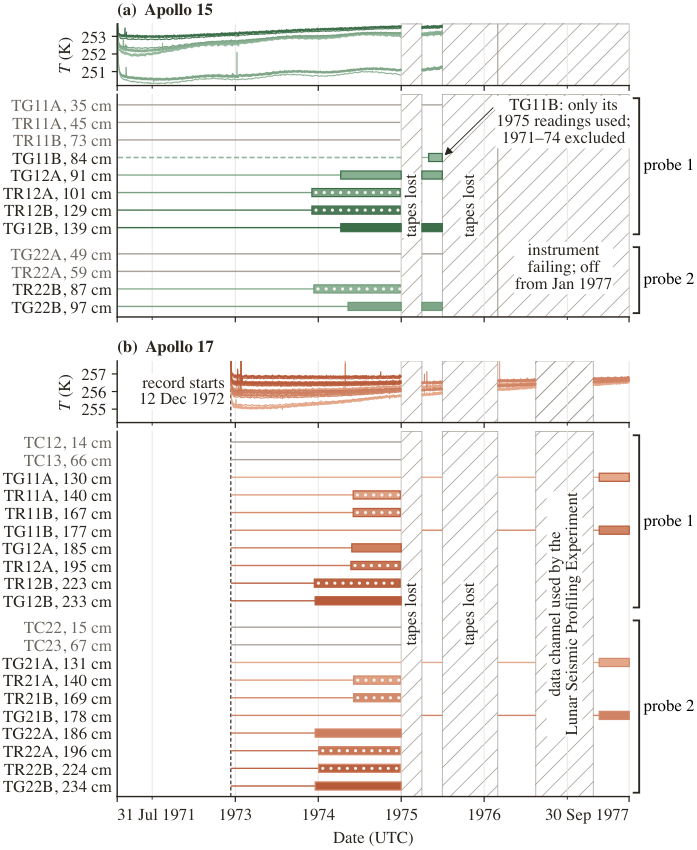

In [15]:
nb.show("fig_joint_apollo_timeline_probes", width=700)

**SI Figure S2.** The heat-flow probe (Langseth and Keihm, 1977, Appendix C,
Figure 1): gradient sensors (TG) with their heaters at the ends of each half,
remote (ring, TR) sensors between them.

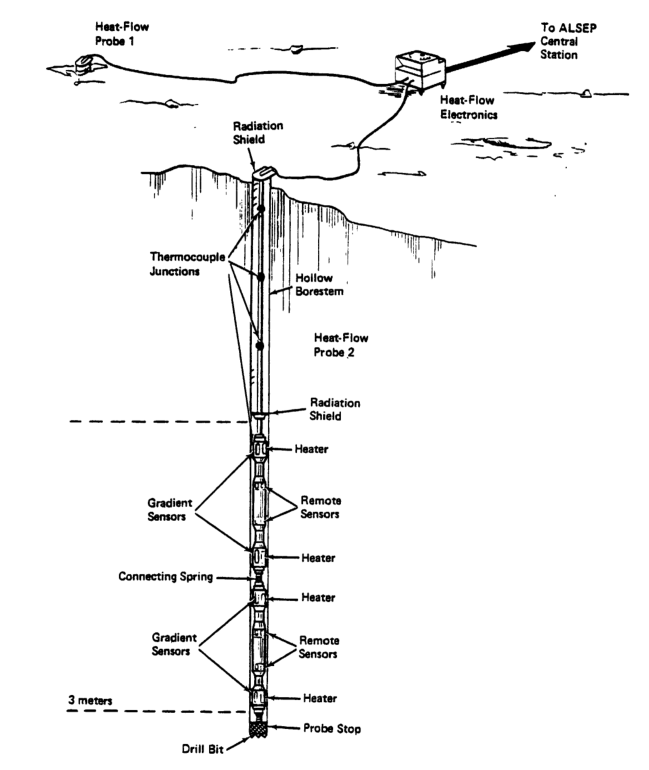

In [16]:
nb.show("fig_probe_drawing", width=450)

**SI Figure S3.** The daily temperature swing against depth: why the
sensors above 80 cm are left out.

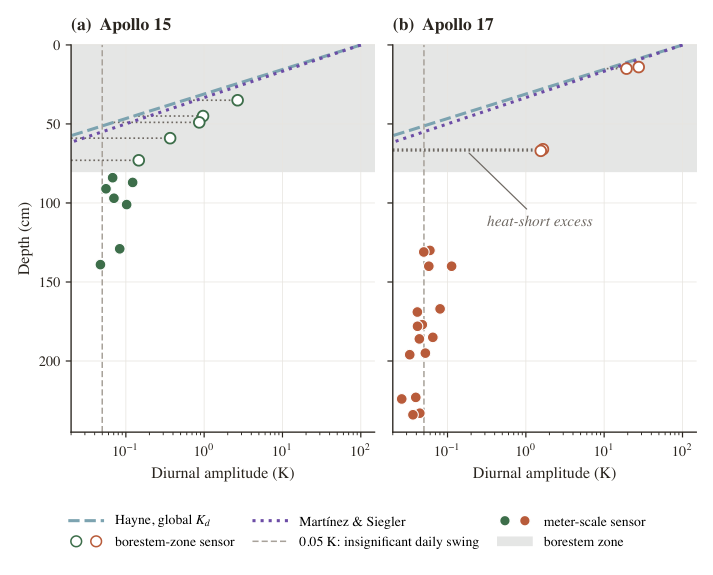

In [17]:
nb.show("fig_joint_amplitude_vs_depth")

## Section 2.2: the thermal model (Figure 2, SI Tables S3, S4, SI Figures S1, S4)
Every fixed input lives in `code/src/lunar/config.py` (SI Table S4). The albedo
and $K_d$ are not inputs: they are fitted. The solver tests (SI Table S3)
repeat the last step of the joint fit with one numerical setting changed at a
time.

In [18]:
from lunar.config import SITES, HAYNE, GRID, DT_STEP
from lunar.constants import RHO_SURFACE, RHO_DEEP
rows = [("latitude (deg N)", SITES["A15"]["lat"], SITES["A17"]["lat"]),
        ("emissivity", SITES["A15"]["emissivity"], SITES["A17"]["emissivity"]),
        ("basal heat flow Q_b (mW m^-2)", SITES["A15"]["Q_BASAL"] * 1e3, SITES["A17"]["Q_BASAL"] * 1e3),
        ("surface conductivity K_s (mW m^-1 K^-1)", HAYNE["K_S"] * 1e3, HAYNE["K_S"] * 1e3),
        ("compaction depth H (cm)", HAYNE["H"] * 100, HAYNE["H"] * 100),
        ("radiative coefficient chi", HAYNE["CHI"], HAYNE["CHI"]),
        ("surface / deep density (kg m^-3)", f"{RHO_SURFACE:.0f} / {RHO_DEEP:.0f}", f"{RHO_SURFACE:.0f} / {RHO_DEEP:.0f}")]
display(pd.DataFrame(rows, columns=["input (SI Table S4)", "Apollo 15", "Apollo 17"]))
print(f"grid: {GRID}   time step: {DT_STEP:.0f} s")
cert = R["joint_numerics_certification"]["sites"]
display(pd.DataFrame({s: {k: f"{v:+.5f}" for k, v in cert[s]["delta_kd_mW"].items()} for s in S2})
        .rename_axis("SI Table S3: change of K_d* (mW m^-1 K^-1)"))

,input (SI Table S4),Apollo 15,Apollo 17
0,latitude (deg N),26.13,20.19
1,emissivity,0.95,0.95
2,basal heat flow Q_b (mW m^-2),21.0,16.0
3,surface conductivity K_s (mW m^-1 K^-1),0.74,0.74
4,compaction depth H (cm),6.0,6.0
5,radiative coefficient chi,2.7,2.7
6,surface / deep density (kg m^-3),1100 / 1800,1100 / 1800


grid: {'z_max': 5.0, 'dz0': 0.002, 'growth': 0.08}   time step: 1800 s


,A15,A17
SI Table S3: change of K_d* (mW m^-1 K^-1),,
nominal,+0.00000,+0.00000
dt_900,+0.00018,+0.00102
dt_450,+0.00025,+0.00141
grid_fine,-0.00016,+0.00238
anchor_0.45,-0.00001,-0.00000
anchor_0.70,+0.00006,+0.00010
n_inner_64,+0.00010,+0.00016
n_inner_128,-0.00001,-0.00001
full_column_A,+0.00021,+0.00058


In [19]:
chk = nb.Checks("Section 2.2, SI Tables S3, S4:")
chk.add("A15: Q_b (mW m^-2)", SITES["A15"]["Q_BASAL"] * 1e3, "21", ".0f")
chk.add("A17: Q_b (mW m^-2)", SITES["A17"]["Q_BASAL"] * 1e3, "16", ".0f")
chk.add("deep density (kg m^-3)", RHO_DEEP, "1800", ".0f")
from lunar.grid import make_geometric_grid
from lunar.config import EQ_Z_ANCHOR
from lunar import constants as cst
grid = make_geometric_grid(**GRID)
chk.add_text("grid: cells to the base (SI Table S3)", str(len(grid.z_center) if hasattr(grid, "z_center") else len(grid.dz)), "69")
chk.add("grid: base depth (m)", GRID["z_max"], "5", ".0f")
chk.add("grid: first cell (mm)", GRID["dz0"] * 1e3, "2", ".0f")
chk.add("grid: growth per cell (%)", GRID["growth"] * 100, "8", ".0f")
chk.add("time step (min)", DT_STEP / 60, "30", ".0f")
chk.add("anchor depth (m)", EQ_Z_ANCHOR, "0.55", ".2f")
import lunar.config as _cfg                          # the anchor method of Section 2.2 (Step A depth = anchor + 0.15 m)
chk.add("anchor method: time-stepped top layer (m)", _cfg.EQ_Z_ANCHOR + 0.15, "0.70", ".2f")
chk.add("anchor method: lunar days per Step A run", _cfg.EQ_N_INNER, "96", ".0f")
chk.add("anchor method: stop when the anchor changes by less than (mK)", _cfg.EQ_ANCHOR_TOL * 1e3, "5", ".0f")
chk.add("solar constant (W m^-2)", cst.SOLAR_CONSTANT, "1361", ".0f")
chk.add("mean synodic month (d)", cst.LUNATION_SECONDS / 86400, "29.531", ".3f")
_ins = nb.load("insolation_check.json")["sites"]
for _s in S2:
    chk.add(f"{_s}: real 1972-1976 sunlight against the idealized cycle, less by (%)", -_ins[_s]["real_minus_ideal_pct"], "0.6", ".1f")
    chk.add_text(f"{_s}:    mostly the Sun-Moon distance at near-side noon", str(abs(_ins[_s]["distance_part_pct"]) > abs(_ins[_s]["geometry_part_pct"])), "True")
chk.add("radiative factor at the sensors, A15", FC["A15"]["effective_conductivity_mW"]["radiative_factor"], "2", ".0f")
chk.add("radiative factor at the sensors, A17", FC["A17"]["effective_conductivity_mW"]["radiative_factor"], "2", ".0f")
chk.add("chi", HAYNE["CHI"], "2.7", ".1f")
mx = lambda key: max(cert[s]["summary"][key] for s in S2)
chk.add("SI Table S3: length of each shallow run", mx("n_inner_max"), "0.0002", ".4f")
chk.add("SI Table S3: Step A on the full column", mx("full_column"), "0.0006", ".4f")
chk.add("SI Table S3: time step halved", mx("dt_per_halving_max"), "0.001", ".3f")
chk.add("SI Table S3: finer grid", mx("grid_fine"), "0.0024", ".4f")
chk.add("SI Table S3: anchor depth", mx("anchor_max"), "0.0001", ".4f")
chk.add("SI Table S3: K_d spacing", mx("kd_spacing"), "0.0003", ".4f")
chk.add("starting temperature: profiles change by about (K)", mx("start_profile_max_K"), "1e-5", ".0e")
chk.show()

Section 2.2, SI Tables S3, S4:


quantity,this repository,paper,match
A15: Q_b (mW m^-2),21,21,✓
A17: Q_b (mW m^-2),16,16,✓
deep density (kg m^-3),1800,1800,✓
grid: cells to the base (SI Table S3),69,69,✓
grid: base depth (m),5,5,✓
grid: first cell (mm),2,2,✓
grid: growth per cell (%),8,8,✓
time step (min),30,30,✓
anchor depth (m),0.55,0.55,✓
anchor method: time-stepped top layer (m),0.70,0.70,✓


All values match the paper.


True

**Figure 2.** The model column, the probes and the two conductivity models.

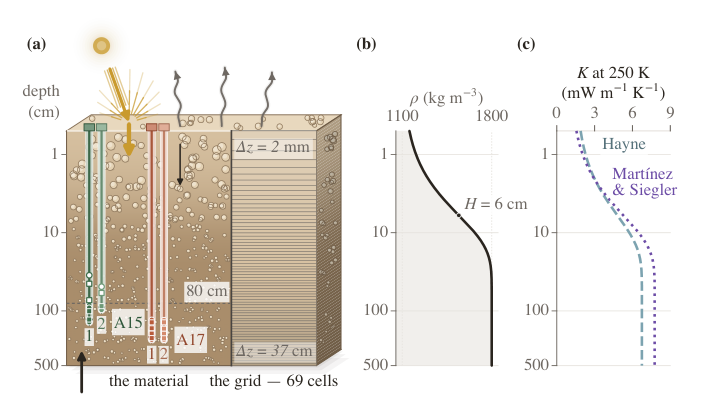

In [20]:
nb.show("fig_joint_intro_column")

**SI Figure S1** (needs the LOLA map) and **SI Figure S4** (the solver at
the joint fit, step by step).

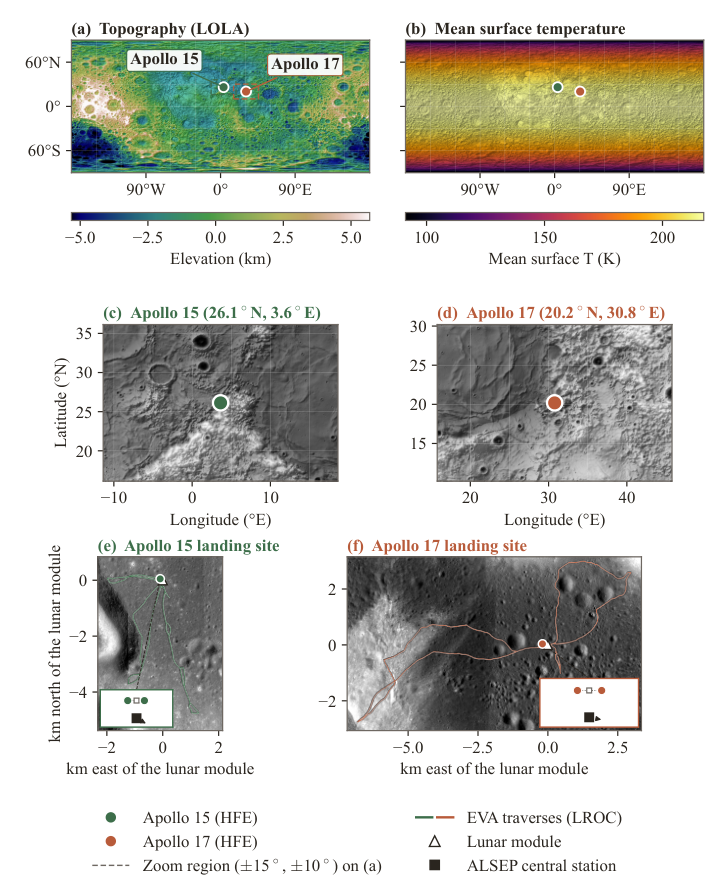

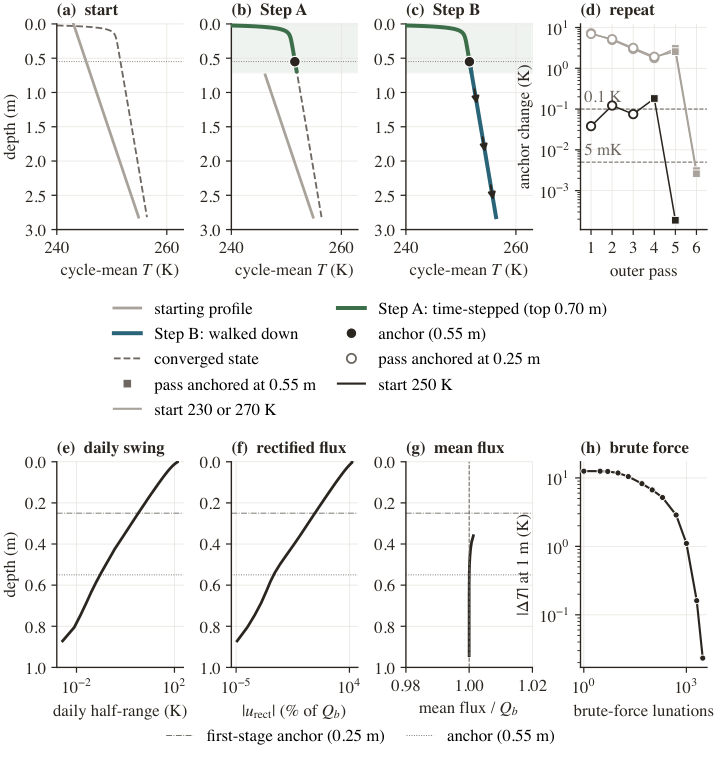

In [21]:
for f in ("fig_context_map", "fig_joint_anchor_process"):
    nb.show(f, width=750)

## Section 2.3: fitting $K_d$
The misfit $J$ (Equation 10) is evaluated on 25 albedos × 94 values of $K_d$ (SI Table S3);
the bootstrap repeats the fit 1500 times with the sensors resampled, each depth
jittered by 2.5 cm and the surface mean and diffusivities redrawn. Its 95%
intervals agree with those of the profile likelihood, and grouping the sensors
by probe hardly changes them (SI Table S5).

In [22]:
m = JF["meta"]
bb = R["joint_block_bootstrap"]["schemes"]
prof = max(abs(JF["sites"][s]["with_diffusivity"]["profile_kd"]["sets_mW"]["dJ<=3.84"][0][i]
               - JF["sites"][s]["with_diffusivity"]["bootstrap"]["kd_mW"][q])
           for s in S2 for i, q in ((0, "p2.5"), (1, "p97.5")))
block = max(abs(bb["probe_block"][s]["kd_mW"][q] - bb["production"][s]["kd_mW"][q]) for s in S2 for q in ("p2.5", "p97.5"))
chk = nb.Checks("Section 2.3:")
chk.add_text("albedos x K_d values (SI Table S3)", f"{len(m['A_grid'])} x {len(m['kd_grid_mW'])}", "25 x 94")
chk.add_text("albedo grid (SI Table S3)", f"{min(m['A_grid']):.3f}-{max(m['A_grid']):.3f}", "0.115-0.175")
chk.add_text("K_d grid, mW m^-1 K^-1 (SI Table S3)", f"{min(m['kd_grid_mW']):g}-{max(m['kd_grid_mW']):g}", "1-24")
chk.add_text("bootstrap repeats", str(m["n_boot"]), "1500")
chk.add("depth jitter (cm)", m["depth_jitter_cm"], "2.5", ".1f")
chk.add("profile likelihood vs bootstrap: 95% bounds agree to", prof, "0.02", ".2f")
chk.add("sensors grouped by probe: 95% bounds move by at most", block, "0.04", ".2f")
chk.show()

Section 2.3:


quantity,this repository,paper,match
albedos x K_d values (SI Table S3),25 x 94,25 x 94,✓
albedo grid (SI Table S3),0.115-0.175,0.115-0.175,✓
"K_d grid, mW m^-1 K^-1 (SI Table S3)",1-24,1-24,✓
bootstrap repeats,1500,1500,✓
depth jitter (cm),2.5,2.5,✓
profile likelihood vs bootstrap: 95% bounds agree to,0.02,0.02,✓
sensors grouped by probe: 95% bounds move by at most,0.04,0.04,✓


All values match the paper.


True

## Section 3.1: each probe, each thermometer type and all the sensors (Table 1, Figure 3)
Each probe fitted as if it were a borehole of its own: its meter-scale sensors,
the surface mean and its own annual-wave diffusivity. A15 probe 2 has two
sensors below the cut, so its albedo is held at the all-sensor value.

In [23]:
SF = R["subset_fits"]["sites"]
rows = [(s, k, f["n_sensors"], f["probes_diffusivity"], f["albedo_fixed"], round(f["A"], 4), round(f["kd_mW"], 2),
         f'{f["kd_bootstrap_mW"]["p2.5"]:.2f} - {f["kd_bootstrap_mW"]["p97.5"]:.2f}', round(f["sensor_rmse_K"], 2),
         f'{f["global_3p4"]["p"]:.1e}') for s in S2 for k, f in SF[s].items() if k != "sensors"]
display(pd.DataFrame(rows, columns=["site", "subset", "sensors", "diffusivity of probe", "albedo held", "A", "K_d",
                                    "K_d, 95%", "RMSE (K)", "p of K_d = 3.4"]))

,site,subset,sensors,diffusivity of probe,albedo held,A,K_d,"K_d, 95%",RMSE (K),p of K_d = 3.4
0,A15,probe1,5,[1],False,0.1301,5.47,4.66 - 6.32,0.28,5.7e-07
1,A15,probe2,2,[2],True,0.1363,4.46,3.72 - 5.22,1.33,9.8e-03
2,A15,TG,4,"[1, 2]",False,0.1345,4.87,4.29 - 5.51,0.91,7.3e-07
3,A15,TR,3,"[1, 2]",False,0.1388,4.86,4.18 - 5.57,0.85,1.3e-06
4,A15,all,7,"[1, 2]",False,0.1363,4.87,4.29 - 5.47,0.90,9.3e-07
5,A17,probe1,8,[1],False,0.1397,6.24,5.34 - 8.43,0.42,6.1e-10
6,A17,probe2,8,[2],False,0.1353,5.67,4.78 - 6.60,0.36,6.7e-07
7,A17,TG,8,"[1, 2]",False,0.1356,5.78,5.13 - 6.43,0.50,5.7e-13
8,A17,TR,8,"[1, 2]",False,0.1392,5.80,5.13 - 6.42,0.30,3.1e-13
9,A17,all,16,"[1, 2]",False,0.1375,5.89,5.26 - 6.51,0.43,1.1e-14


In [24]:
chk = nb.Checks("Section 3.1, each probe on its own:")
chk.add_text("A15 probe 2: sensors (albedo held)", f'{SF["A15"]["probe2"]["n_sensors"]} ({SF["A15"]["probe2"]["albedo_fixed"]})', "2 (True)")
chk.add("A15 probe 2: p of K_d = 3.4", SF["A15"]["probe2"]["global_3p4"]["p"], "0.01", ".2f")
chk.add("the other probes: largest p of K_d = 3.4", max(SF[s][k]["global_3p4"]["p"] for s, k in (("A15", "probe1"), ("A17", "probe1"), ("A17", "probe2"))), "<1e-6")
chk.add_text("every albedo fitted to a subset (albedo free)", nb.span([SF[s][k]["A"] for s in S2 for k in ("probe1", "probe2", "TG", "TR", "all") if not SF[s][k]["albedo_fixed"]], ".3f"), "0.130-0.140")
chk.add_text("every probe and every thermometer type on its own (Section 3.1, abstract)", nb.span([SF[s][k]["kd_mW"] for s in S2 for k in ("probe1", "probe2", "TG", "TR")], ".1f"), "4.5-6.2")
chk.show()

Section 3.1, each probe on its own:


quantity,this repository,paper,match
A15 probe 2: sensors (albedo held),2 (True),2 (True),✓
A15 probe 2: p of K_d = 3.4,0.01,0.01,✓
the other probes: largest p of K_d = 3.4,6.7e-07,<1e-6,✓
every albedo fitted to a subset (albedo free),0.130-0.140,0.130-0.140,✓
"every probe and every thermometer type on its own (Section 3.1, abstract)",4.5-6.2,4.5-6.2,✓


All values match the paper.


True

**Table 1**, upper rows, every entry: sensors, albedo, $K_d$ with its 95%
interval, the misfit and mean bias at the subset's own sensors, the model
diffusivity, the misfit of the global value with the albedo refitted, and its
probability.

In [25]:
T1 = {  # site, subset: sensors, A, K_d, lower, upper, RMSE, bias, kappa, RMSE at 3.4, p (as printed in Table 1)
    ("A15", "probe1"): ("5", "0.130", "5.5", "4.7", "6.3", "0.28", "0.00", "0.90", "0.52", "6e-7"),
    ("A15", "probe2"): ("2", "0.136", "4.5", "3.7", "5.2", "1.33", "+1.33", "0.74", "1.42", "0.01"),
    ("A15", "TG"): ("4", "0.134", "4.9", "4.3", "5.5", "0.91", "-0.01", "0.80", "0.97", "7e-7"),
    ("A15", "TR"): ("3", "0.139", "4.9", "4.2", "5.6", "0.85", "-0.01", "0.80", "0.76", "1e-6"),
    ("A15", "all"): ("7", "0.136", "4.9", "4.3", "5.5", "0.90", "0.00", "0.80", "0.90", "9e-7"),
    ("A17", "probe1"): ("8", "0.140", "6.2", "5.3", "8.4", "0.42", "0.00", "1.04", "0.72", "6e-10"),
    ("A17", "probe2"): ("8", "0.135", "5.7", "4.8", "6.6", "0.36", "0.00", "0.94", "0.66", "7e-7"),
    ("A17", "TG"): ("8", "0.136", "5.8", "5.1", "6.4", "0.50", "0.00", "0.96", "0.83", "6e-13"),
    ("A17", "TR"): ("8", "0.139", "5.8", "5.1", "6.4", "0.30", "-0.01", "0.96", "0.53", "3e-13"),
    ("A17", "all"): ("16", "0.137", "5.9", "5.3", "6.5", "0.43", "0.00", "0.98", "0.71", "1e-14")}
chk = nb.Checks("Table 1, upper rows:")
for (s, k), (n, A, kd, lo, hi, rm, bi, ka, r34, pv) in T1.items():
    f = SF[s][k]; kb = f["kd_bootstrap_mW"]
    chk.add_text(f"{s} {k}: sensors", str(f["n_sensors"]), n)
    chk.add(f"{s} {k}: A", f["A"], A, ".3f")
    chk.add(f"{s} {k}: K_d", f["kd_mW"], kd, ".1f")
    chk.add(f"{s} {k}: 95% lower", kb["p2.5"], lo, ".1f")
    chk.add(f"{s} {k}: 95% upper", kb["p97.5"], hi, ".1f")
    chk.add(f"{s} {k}: RMSE (K)", f["sensor_rmse_K"], rm, ".2f")
    chk.add(f"{s} {k}: bias (K)", f["bias_K"], bi, "+.2f" if bi.startswith("+") else ".2f")
    chk.add(f"{s} {k}: kappa", np.mean(f["kappa_model"]), ka, ".2f")
    chk.add(f"{s} {k}: RMSE at K_d = 3.4, A refitted (K)", f["global_3p4"]["sensor_rmse_K"], r34, ".2f")
    chk.add(f"{s} {k}: p of K_d = 3.4", f["global_3p4"]["p"], pv, ".2f" if pv == "0.01" else ".0e")
chk.add("model diffusivity at K_d = 3.4, every subset and probe: lowest", min(min(SF[s][k]["global_3p4"]["kappa_model"]) for s in S2 for k in SF[s] if k != "sensors"), "0.56", ".2f")
chk.add("   highest", max(max(SF[s][k]["global_3p4"]["kappa_model"]) for s in S2 for k in SF[s] if k != "sensors"), "0.56", ".2f")
chk.add("A15: K_d = 3.4 vs each subset's own fit, all but probe 1: largest RMSE difference (K)", max(abs(SF["A15"][k]["global_3p4"]["sensor_rmse_K"] - SF["A15"][k]["sensor_rmse_K"]) for k in ("probe2", "TG", "TR", "all")), "0.1", ".1f")
chk.add_text("A17: K_d = 3.4 fits every subset worse by (K)", nb.span([SF["A17"][k]["global_3p4"]["sensor_rmse_K"] - SF["A17"][k]["sensor_rmse_K"] for k in ("probe1", "probe2", "TG", "TR", "all")], ".1f"), "0.2-0.3")
chk.add_text("all-sensor rows equal the joint fit", str(all(abs(SF[s]["all"]["kd_mW"] - best[s]["kd_star_mW"]) < 1e-9 for s in S2)), "True")
chk.show()

Table 1, upper rows:


quantity,this repository,paper,match
A15 probe1: sensors,5,5,✓
A15 probe1: A,0.130,0.130,✓
A15 probe1: K_d,5.5,5.5,✓
A15 probe1: 95% lower,4.7,4.7,✓
A15 probe1: 95% upper,6.3,6.3,✓
A15 probe1: RMSE (K),0.28,0.28,✓
A15 probe1: bias (K),0.00,0.00,✓
A15 probe1: kappa,0.90,0.90,✓
"A15 probe1: RMSE at K_d = 3.4, A refitted (K)",0.52,0.52,✓
A15 probe1: p of K_d = 3.4,6e-7,6e-7,✓


All values match the paper.


True

Each sensor minus the joint fit, by probe, thermometer type (TG: gradient
bridge; TR: ring bridge) and the year its window ends. The offsets between the
probes and between the types are what the letter quotes.

In [26]:
for s in S2:
    print(f"Apollo {s[1:]}")
    display(pd.DataFrame(FC[s]["sensor_residuals"]["sensors"]).round(2))
sr15, sr17 = FC["A15"]["sensor_residuals"], FC["A17"]["sensor_residuals"]
type_gap = [sr["type_mean_K"][f"probe{p}_TG"] - sr["type_mean_K"][f"probe{p}_TR"]
            for sr in (sr15, sr17) for p in (1, 2) if f"probe{p}_TR" in sr["type_mean_K"]]
chk = nb.Checks("Section 4.2, the sensors against the all-sensor fit (Figure 3):")
chk.add_text("A15 probe 2: below the all-sensor model by (K)", nb.span([-x for x in sr15["probe_range_K"]["probe2"]], ".1f"), "1.3-1.4")
chk.add("A17 probe 2 minus probe 1, both windows in 1974: up to (K)", max(q["diff_K"] for q in sr17["probe2_minus_probe1_K"]["1974"]), "0.56", ".2f")
chk.add("A17 probe 2 minus probe 1, both windows in 1977: about (K)", max(q["diff_K"] for q in sr17["probe2_minus_probe1_K"]["1977"]), "0.1", ".1f")
chk.add("TR read colder than TG of the same probe, on average by up to (K)", max(type_gap), "0.4", ".1f")
chk.show()

Apollo 15


,probe,sensor,type,depth_cm,year,residual_K
0,1,TG11B,TG,84.0,1975,1.00
1,2,TR22B,TR,87.0,1974,-1.39
2,1,TG12A,TG,91.0,1975,0.80
3,2,TG22B,TG,97.0,1975,-1.32
4,1,TR12A,TR,101.0,1974,0.57
5,1,TR12B,TR,129.0,1974,0.20
6,1,TG12B,TG,139.0,1975,0.15


Apollo 17


,probe,sensor,type,depth_cm,year,residual_K
0,1,TG11A,TG,130.0,1977,0.77
1,2,TG21A,TG,131.0,1977,0.87
2,1,TR11A,TR,140.0,1974,-0.17
3,2,TR21A,TR,140.0,1974,0.40
4,1,TR11B,TR,167.0,1974,-0.31
5,2,TR21B,TR,169.0,1974,0.16
6,1,TG11B,TG,177.0,1977,0.27
7,2,TG21B,TG,178.0,1977,0.40
8,1,TG12A,TG,185.0,1974,-0.37
9,2,TG22A,TG,186.0,1974,0.08


Section 4.2, the sensors against the all-sensor fit (Figure 3):


quantity,this repository,paper,match
A15 probe 2: below the all-sensor model by (K),1.3-1.4,1.3-1.4,✓
"A17 probe 2 minus probe 1, both windows in 1974: up to (K)",0.56,0.56,✓
"A17 probe 2 minus probe 1, both windows in 1977: about (K)",0.1,0.1,✓
"TR read colder than TG of the same probe, on average by up to (K)",0.4,0.4,✓


All values match the paper.


True

**Figure 3.** Each probe, each thermometer type and all the sensors.

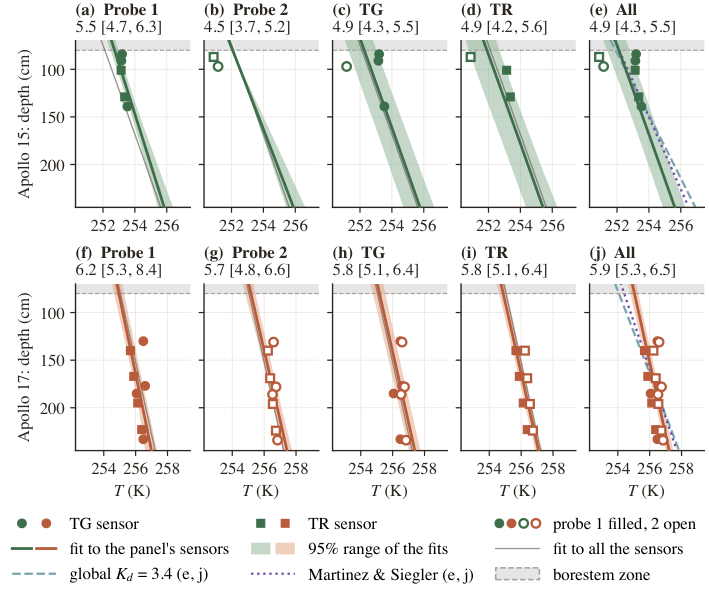

In [27]:
nb.show("fig_joint_subsets")

### Section 3.1, continued: each thermometer type (Figure 3c, d, h, i)
Each thermometer type (TG: gradient bridge; TR: ring bridge) fitted on its own,
with both probes' diffusivities.

In [28]:
chk = nb.Checks("Section 3.1, each thermometer type on its own:")
chk.add("TG and TR give the same K_d to within", max(abs(SF[s]["TG"]["kd_mW"] - SF[s]["TR"]["kd_mW"]) for s in S2), "0.02", ".2f")
chk.add("each type: largest p of K_d = 3.4", max(SF[s][k]["global_3p4"]["p"] for s in S2 for k in ("TG", "TR")), "<2e-6")
chk.show()

Section 3.1, each thermometer type on its own:


quantity,this repository,paper,match
TG and TR give the same K_d to within,0.02,0.02,✓
each type: largest p of K_d = 3.4,1.3e-06,<2e-6,✓


All values match the paper.


True

### Section 3.1, continued: all the sensors together (the joint fit); Section 3.2: the global values are rejected (Table 1, Figure 3e, j)
The values the letter adopts: 4.9 [4.3, 5.5] at Apollo 15 and 5.9 [5.3, 6.5]
mW m⁻¹ K⁻¹ at Apollo 17 (95% bootstrap intervals).

In [29]:
rows = []
for s in S2:
    for fit in ("with_diffusivity", "temperature_only"):
        b, bt = JF["sites"][s][fit]["best"], JF["sites"][s][fit]["bootstrap"]
        rows.append((s, "sensors + surface mean + diffusivity" if fit == "with_diffusivity" else "sensors + surface mean only",
                     round(b["A"], 4), f'{bt["A"]["p2.5"]:.3f} - {bt["A"]["p97.5"]:.3f}',
                     round(b["kd_star_mW"], 2), f'{bt["kd_mW"]["p2.5"]:.2f} - {bt["kd_mW"]["p97.5"]:.2f}'))
display(pd.DataFrame(rows, columns=["site", "fitted to", "albedo A", "A, 95%", "K_d", "K_d, 95%"]))

,site,fitted to,albedo A,"A, 95%",K_d,"K_d, 95%"
0,A15,sensors + surface mean + diffusivity,0.1363,0.128 - 0.145,4.87,4.29 - 5.47
1,A15,sensors + surface mean only,0.1373,0.132 - 0.170,3.72,1.76 - 20.97
2,A17,sensors + surface mean + diffusivity,0.1375,0.135 - 0.140,5.89,5.26 - 6.51
3,A17,sensors + surface mean only,0.1552,0.142 - 0.170,15.66,8.52 - 24.00


In [30]:
kobs = JF["meta"]["kappa_obs_langseth1976_table1"]
zsig = max(abs(km - o[2]) / o[3] for s in S2 for km, o in zip(FC[s]["fit_with_diffusivity"]["kappa_model"], kobs[s]))
va = R["joint_valley"]["A17"]["rows"]; r6, r7 = (next(r for r in va if r["kd_mW"] == k) for k in (6.0, 7.0))
sa = LR["standard_albedo_0p12"]
chk = nb.Checks("Sections 3.1, 3.3, the joint fit:")
for s, A, lo_a, hi_a, kd, lo, hi in (("A15", "0.136", "0.128", "0.145", "4.9", "4.3", "5.5"),
                                     ("A17", "0.137", "0.135", "0.140", "5.9", "5.3", "6.5")):
    w = JF["sites"][s]["with_diffusivity"]
    chk.add(f"{s}: A*", w["best"]["A"], A, ".3f")
    chk.add(f"{s}: A* 95% lower", w["bootstrap"]["A"]["p2.5"], lo_a, ".3f")
    chk.add(f"{s}: A* 95% upper", w["bootstrap"]["A"]["p97.5"], hi_a, ".3f")
    chk.add(f"{s}: K_d*", w["best"]["kd_star_mW"], kd, ".1f")
    chk.add(f"{s}: K_d* 95% lower", w["bootstrap"]["kd_mW"]["p2.5"], lo, ".1f")
    chk.add(f"{s}: K_d* 95% upper", w["bootstrap"]["kd_mW"]["p97.5"], hi, ".1f")
chk.add_text("K_d* / global value", nb.span([best[s]["kd_star_mW"] / 3.4 for s in S2], ".1f"), "1.4-1.7")
_hw = [abs(JF["sites"][s]["with_diffusivity"]["bootstrap"]["kd_mW"][q] - best[s]["kd_star_mW"]) for s in S2 for q in ("p2.5", "p97.5")]
chk.add("abstract: the 95% intervals written as +- (smallest half-width, both sites)", min(_hw), "0.6", ".1f")
chk.add("abstract: the 95% intervals written as +- (largest half-width, both sites)", max(_hw), "0.6", ".1f")
chk.add("modeled surface means within 5 K of the measured ones: largest difference (K)",
        max(abs(FC[s]["fit_with_diffusivity"]["surface_mean_K"] - JF["sites"][s]["with_diffusivity"]["best"]["surface_mean_obs_K"]) for s in S2), "<5")
chk.add("model diffusivities agree with the measured ones within (standard errors)", zsig, "1.3", ".1f")
chk.add("A17 valley: K_d 6 -> 7 barely changes the sensor misfit (K)", r6["sensor_rmse_K"] - r7["sensor_rmse_K"], "<0.05")
chk.add_text("   but moves the diffusivity above the probes by (standard errors)", nb.span(r7["kappa_sigmas"], ".0f"), "2-4")
chk.add_text("fitted albedo above 0.12 by", nb.span([best[s]["A"] - 0.12 for s in S2], ".3f"), "0.016-0.017")
chk.add_text("A* 95% interval narrower at A17 than at A15", str(all(JF["sites"]["A17"]["with_diffusivity"]["bootstrap"]["A"][q] - JF["sites"]["A17"]["with_diffusivity"]["bootstrap"]["A"]["p2.5"] <
             JF["sites"]["A15"]["with_diffusivity"]["bootstrap"]["A"][q] - JF["sites"]["A15"]["with_diffusivity"]["bootstrap"]["A"]["p2.5"] for q in ("p97.5",))), "True")
b012 = [next(c["bias_K"] for c in R["albedo_sensitivity"]["cases"] if c["site"] == s and c["family"] == "constant" and abs(c["A"] - 0.12) < 1e-9) for s in S2]
chk.add("albedo held at 0.12, temperatures alone: model warmer than the sensors, both sites, about (K)", np.mean(b012), "1.4", ".1f")
chk.add("albedo held at 0.12 against the fitted albedo: largest p", max(sa[s]["fixed_vs_fitted_albedo"]["p"] for s in S2), "<0.005")
chk.show()

Sections 3.1, 3.3, the joint fit:


quantity,this repository,paper,match
A15: A*,0.136,0.136,✓
A15: A* 95% lower,0.128,0.128,✓
A15: A* 95% upper,0.145,0.145,✓
A15: K_d*,4.9,4.9,✓
A15: K_d* 95% lower,4.3,4.3,✓
A15: K_d* 95% upper,5.5,5.5,✓
A17: A*,0.137,0.137,✓
A17: A* 95% lower,0.135,0.135,✓
A17: A* 95% upper,0.140,0.140,✓
A17: K_d*,5.9,5.9,✓


All values match the paper.


True

In [31]:
st_ = LR["sites"]
pv = LR["diffusivity_uncertainty_doubled"]
chk = nb.Checks("Section 3.2, the global values are rejected:")
chk.add("A15, temperatures alone: p", st_["A15"]["global_3p4_temperature_only"]["p"], "0.85", ".2f")
chk.add("A15: diffusivity at K_d = 3.4", np.mean(FC["A15"]["global_3p4"]["kappa_model"]), "0.56", ".2f")
chk.add_text("measured diffusivities, all four probes", nb.span([o[2] for s in S2 for o in JF["meta"]["kappa_obs_langseth1976_table1"][s]], ".2f"), "0.74-1.00")
chk.add("3.4 and the 3.8 of Feng et al. (2020), both sites: largest p", max([st_[s]["global_3p4_with_diffusivity"]["p"] for s in S2] +
        [st_[s]["published_global_values"]["feng2020"]["p"] for s in S2]), "<1e-3")
chk.add("3.4 with the diffusivity errors doubled, both sites: p (still rejected)", pv["pooled"]["p"], "<1e-3")
chk.add("all sensors, both sites: largest p of 3.4 (abstract)", max(R["subset_fits"]["sites"][s]["all"]["global_3p4"]["p"] for s in S2), "<1e-6")
gt = LR["global_3p4_terms"]                         # the rejection without the sensor term
chk.add("A15: the diffusivity term alone rejects 3.4, p", gt["A15"]["diffusivity_alone"]["p"], "9e-7", ".0e")
chk.add("A17: the diffusivity term alone rejects 3.4, p", gt["A17"]["diffusivity_alone"]["p"], "5e-11", ".0e")
chk.show()

Section 3.2, the global values are rejected:


quantity,this repository,paper,match
"A15, temperatures alone: p",0.85,0.85,✓
A15: diffusivity at K_d = 3.4,0.56,0.56,✓
"measured diffusivities, all four probes",0.74-1.00,0.74-1.00,✓
"3.4 and the 3.8 of Feng et al. (2020), both sites: largest p",0.00035,<1e-3,✓
"3.4 with the diffusivity errors doubled, both sites: p (still rejected)",4.5e-08,<1e-3,✓
"all sensors, both sites: largest p of 3.4 (abstract)",9.3e-07,<1e-6,✓
"A15: the diffusivity term alone rejects 3.4, p",9e-7,9e-7,✓
"A17: the diffusivity term alone rejects 3.4, p",5e-11,5e-11,✓


All values match the paper.


True

In [32]:
ob = GE["sites"]["A17"]["observed"]
tws = R["transient_warming"]["sites"]["A17"]["cases"]["step_1.6K"]["surface_as_measured"]
chk = nb.Checks("Section 4.3, the Apollo 17 gradient:")
chk.add("above the common-epoch value by (standard errors)", ob["common_1974"]["tension_sigma"]["joint_fit"], "2.5", ".1f")
chk.add("above the per-sensor value by (standard errors)", ob["certified"]["tension_sigma"]["joint_fit"], "4.2", ".1f")
chk.add("measured gradient with the warming removed: below the model by about (standard errors)",
        (GE["sites"]["A17"]["model_gradient_K_per_m"]["joint_fit"] - tws["gradient_observed_corrected_K_per_m"]) / ob["certified"]["se"], "1", ".0f")
chk.show()

Section 4.3, the Apollo 17 gradient:


quantity,this repository,paper,match
above the common-epoch value by (standard errors),2.5,2.5,✓
above the per-sensor value by (standard errors),4.2,4.2,✓
measured gradient with the warming removed: below the model by about (standard errors),1,1,✓


All values match the paper.


True

**The models against all the sensors** (Table 1, lower rows; Figure 3e, j). At its published
values ($K_d=3.4$, $A=0.12$) the Hayne et al. (2017) model runs warmer than the
sensors. Refitting the albedo removes the offset; at Apollo 15 the global value
then fits the sensors as well as the recalibrated $K_d$, but at Apollo 17 it
predicts a gradient two to six times the measured one.

In [33]:
rows = []
for s in S2:
    h = LR["standard_albedo_0p12"][s]["hayne_as_published"]
    rows.append((s, "Hayne, published values", 0.12, 3.4, h["sensor_rmse_K"], h["sensor_bias_K"], np.mean(h["kappa_model_1e4_cm2_s"])))
    for key, name in (("global_3p4", "Hayne, K_d = 3.4, A refitted"), ("fit_with_diffusivity", "Hayne, joint fit"),
                      ("martinez_forward", "Martinez & Siegler")):
        r = FC[s][key]
        rows.append((s, name, r["A"], r.get("kd_mW"), r["rmse_K"], r["bias_K"], np.mean(r["kappa_model"]) if "kappa_model" in r else None))
display(pd.DataFrame(rows, columns=["site", "model (Table 1)", "A", "K_d", "RMSE (K)", "bias (K)", "kappa (1e-4 cm^2/s)"]).round(3))

,site,model (Table 1),A,K_d,RMSE (K),bias (K),kappa (1e-4 cm^2/s)
0,A15,"Hayne, published values",0.120,3.400,1.775,1.527,0.563
1,A15,"Hayne, K_d = 3.4, A refitted",0.138,3.400,0.905,0.018,0.561
2,A15,"Hayne, joint fit",0.136,4.867,0.902,-0.002,0.803
3,A15,Martinez & Siegler,0.136,NaN,0.910,0.141,NaN
4,A17,"Hayne, published values",0.120,3.400,2.088,1.966,0.568
5,A17,"Hayne, K_d = 3.4, A refitted",0.143,3.400,0.711,0.013,0.564
6,A17,"Hayne, joint fit",0.137,5.893,0.432,-0.003,0.980
7,A17,Martinez & Siegler,0.137,NaN,0.624,0.049,NaN


In [34]:
chk = nb.Checks("Table 1, lower rows (and the all-sensor row from the joint-fit checks):")
P = {"A15": dict(pub=("1.77", "+1.53", "0.56"), glob=("0.138", "0.90", "+0.02", "0.56"),
                 fit=("0.136", "0.90", "0.00", "0.80"), ms=("0.136", "0.91", "+0.14")),
     "A17": dict(pub=("2.09", "+1.97", "0.57"), glob=("0.143", "0.71", "+0.01", "0.56"),
                 fit=("0.137", "0.43", "0.00", "0.98"), ms=("0.137", "0.62", "+0.05"))}
for s in S2:
    p, h = P[s], LR["standard_albedo_0p12"][s]["hayne_as_published"]
    chk.add(f"{s} published values: RMSE (K)", h["sensor_rmse_K"], p["pub"][0], ".2f")
    chk.add(f"{s} published values: bias (K)", h["sensor_bias_K"], p["pub"][1], "+.2f")
    chk.add(f"{s} published values: kappa", np.mean(h["kappa_model_1e4_cm2_s"]), p["pub"][2], ".2f")
    g = FC[s]["global_3p4"]
    chk.add(f"{s} K_d=3.4, A refitted: RMSE equals the all-sensor row's 'K_d = 3.4' column (K)", g["rmse_K"], p["glob"][1], ".2f")
    f = FC[s]["fit_with_diffusivity"]
    chk.add(f"{s} joint fit: A", f["A"], p["fit"][0], ".3f")
    chk.add(f"{s} joint fit: RMSE (K)", f["rmse_K"], p["fit"][1], ".2f")
    chk.add(f"{s} joint fit: bias (K)", f["bias_K"], p["fit"][2], ".2f")
    chk.add(f"{s} joint fit: kappa", np.mean(f["kappa_model"]), p["fit"][3], ".2f")
    chk.add(f"{s} Martinez & Siegler: A", FC[s]["martinez_forward"]["A"], p["ms"][0], ".3f")
    chk.add(f"{s} Martinez & Siegler: RMSE (K)", FC[s]["martinez_forward"]["rmse_K"], p["ms"][1], ".2f")
    chk.add(f"{s} Martinez & Siegler: bias (K)", FC[s]["martinez_forward"]["bias_K"], p["ms"][2], "+.2f")
chk.show()

Table 1, lower rows (and the all-sensor row from the joint-fit checks):


quantity,this repository,paper,match
A15 published values: RMSE (K),1.77,1.77,✓
A15 published values: bias (K),+1.53,+1.53,✓
A15 published values: kappa,0.56,0.56,✓
"A15 K_d=3.4, A refitted: RMSE equals the all-sensor row's 'K_d = 3.4' column (K)",0.90,0.90,✓
A15 joint fit: A,0.136,0.136,✓
A15 joint fit: RMSE (K),0.90,0.90,✓
A15 joint fit: bias (K),0.00,0.00,✓
A15 joint fit: kappa,0.80,0.80,✓
A15 Martinez & Siegler: A,0.136,0.136,✓
A15 Martinez & Siegler: RMSE (K),0.91,0.91,✓


All values match the paper.


True

In [35]:
ob = GE["sites"]["A17"]["observed"]
gt = FC["A17"]["global_residual_trend"]
al = [c for c in R["albedo_sensitivity"]["cases"] if c["site"] == "A17"
      and abs(c["bias_K"]) <= 1 and abs(c["surface_mean_K"] - c["surface_mean_obs_K"]) <= 5]
ratios = [GE["sites"]["A17"]["model_gradient_K_per_m"]["global_3p4"] / ob[k]["gradient_K_per_m"]
          for k in ("certified", "common_1974", "translated_1974", "thermoluminescence")]
chk = nb.Checks("Section 3.2, the global value against all the sensors:")
chk.add("published values run warmer than the sensors, A15 (K)", LR["standard_albedo_0p12"]["A15"]["hayne_as_published"]["sensor_bias_K"], "1.5", ".1f")
chk.add("published values run warmer than the sensors, A17 (K)", LR["standard_albedo_0p12"]["A17"]["hayne_as_published"]["sensor_bias_K"], "2.0", ".1f")
chk.add("A17 global value: residuals rise from the shallowest to the deepest sensor by about (K)", gt["deep_K"] - gt["shallow_K"], "2", ".0f")
chk.add("A17 measured gradient, per-sensor windows", ob["certified"]["gradient_K_per_m"], "0.37", ".2f")
chk.add("   its standard error", ob["certified"]["se"], "0.23", ".2f")
chk.add("   its standard error", max(ob["common_1974"]["se"], ob["translated_1974"]["se"]), "0.2", ".1f")
chk.add("A17 drill-core gradient (Sehlke et al., 2026)", ob["thermoluminescence"]["gradient_K_per_m"], "1.0", ".1f")
chk.add("   its uncertainty", ob["thermoluminescence"]["se"], "0.5", ".1f")
chk.add_text("global gradient / measured: two to six times", f"{nb.rounded(min(ratios), '.0f')}-{nb.rounded(max(ratios), '.0f')}", "2-6")
chk.add("A15 measured gradient (K/m)", GE["sites"]["A15"]["observed"]["certified"]["gradient_K_per_m"], "2.54", ".2f")
chk.add("   its standard error", GE["sites"]["A15"]["observed"]["certified"]["se"], "2.02", ".2f")
chk.add("A15 gradient, global value (K/m)", GE["sites"]["A15"]["model_gradient_K_per_m"]["global_3p4"], "3.06", ".2f")
chk.show()

Section 3.2, the global value against all the sensors:


quantity,this repository,paper,match
"published values run warmer than the sensors, A15 (K)",1.5,1.5,✓
"published values run warmer than the sensors, A17 (K)",2.0,2.0,✓
A17 global value: residuals rise from the shallowest to the deepest sensor by about (K),2,2,✓
"A17 measured gradient, per-sensor windows",0.37,0.37,✓
its standard error,0.23,0.23,✓
its standard error,0.2,0.2,✓
"A17 drill-core gradient (Sehlke et al., 2026)",1.0,1.0,✓
its uncertainty,0.5,0.5,✓
global gradient / measured: two to six times,2-6,2-6,✓
A15 measured gradient (K/m),2.54,2.54,✓


All values match the paper.


True

## Section 3.3: what fixes $K_d$ (Figure 4, SI Figure S5; SI Tables S7–S11)
On their own, the temperatures leave $K_d$ open or tie it to an assumed albedo;
the annual wave fixes it through how the wave fades and lags with depth.

**Sensor temperatures at a fixed albedo** (SI Table S7).

In [36]:
cases = R["albedo_sensitivity"]["cases"]
const = {s: {round(c["A"], 4): c["kd_star_mW"] for c in cases if c["site"] == s and c["family"] == "constant"} for s in S2}
mapc = {s: next(c["kd_star_mW"] for c in cases if c["site"] == s and c["family"] == "angular" and c["f"] == 0.0) for s in S2}
laws = [c["kd_star_mW"] for c in cases if c["family"] == "angular" and c["f"] == 1.0] + \
       [e["kd_star_mW"] for e in R["albedo_anchor"]["published_laws_at_sites"]]
display(pd.DataFrame({s: pd.Series(const[s]) for s in S2}).rename_axis("fixed albedo").round(2).T)
chk = nb.Checks("Section 3.3, a fixed albedo:")
for s, k012, kmap in (("A15", "4.6", "4.6"), ("A17", "5.8", "5.7")):
    chk.add(f"{s}: albedo 0.12", const[s][0.12], k012, ".1f")
    chk.add(f"{s}: map albedo of the site", mapc[s], kmap, ".1f")
scan = [v for s in S2 for a, v in const[s].items() if 0.08 <= a <= 0.16]
chk.add("albedo 0.08-0.16, both sites: lowest", min(scan), "2.9", ".1f")
chk.add("   highest", max(scan), "18", ".0f")
chk.add("published angular albedo laws, lowest", min(laws), "0.9", ".1f")
chk.add("published angular albedo laws, highest (grid edge)", max(laws), "27", ".0f")
chk.show()

fixed albedo,0.0800,0.0900,0.1000,0.1100,0.1200,0.1225,0.1250,0.1275,0.1300,0.1310,...,0.1475,0.1500,0.1525,0.1550,0.1575,0.1600,0.1700,0.1800,0.1900,0.2000
A15,4.63,4.63,4.64,4.64,4.64,4.64,4.63,4.62,4.61,4.60,...,10.45,11.51,12.58,13.67,14.79,15.94,20.97,26.86,27.0,1.10
A17,5.63,5.65,5.67,5.71,5.78,5.81,5.84,5.90,5.99,6.04,...,12.03,13.22,14.43,15.68,16.95,18.27,24.05,27.00,27.0,1.41


Section 3.3, a fixed albedo:


quantity,this repository,paper,match
A15: albedo 0.12,4.6,4.6,✓
A15: map albedo of the site,4.6,4.6,✓
A17: albedo 0.12,5.8,5.8,✓
A17: map albedo of the site,5.7,5.7,✓
"albedo 0.08-0.16, both sites: lowest",2.9,2.9,✓
highest,18,18,✓
"published angular albedo laws, lowest",0.9,0.9,✓
"published angular albedo laws, highest (grid edge)",27,27,✓


All values match the paper.


True

**Sensor temperatures and the surface mean, with the albedo free** (Figure 4,
SI Tables S8, S9). The temperatures allow a long valley of solutions; this is
also why the global value passed the original ±5 K test.

In [37]:
to = {s: JF["sites"][s]["temperature_only"] for s in S2}
tw = R["transient_warming"]["sites"]["A17"]["cases"]["step_1.6K"]["surface_as_measured"]["temperature_only"]
kt = R["joint_probe_checks"]["sites"]
chk = nb.Checks("Section 3.3, temperatures alone:")
chk.add_text("A15: 68% interval (profile likelihood)", nb.span(to["A15"]["profile_kd"]["sets_mW"]["dJ<=1.0"][0], ".1f"), "2.4-6.7")
chk.add("A17: bounded from below at (bootstrap 2.5%)", to["A17"]["bootstrap"]["kd_mW"]["p2.5"], "8.5", ".1f")
chk.add("A17, the warming after deployment removed: K_d", tw["kd_mW"], "7.4", ".1f")
chk.add("   95% lower", tw["interval95_mW"][0], "6.5", ".1f")
chk.add("   95% upper", tw["interval95_mW"][1], "9.3", ".1f")
for s, lo, hi in (("A15", "1.3", "6.5"), ("A17", "1.3", "10.3")):
    k = kt[s]["keihm_test_A_0.12"]["kd_pass_mW"]
    chk.add(f"{s}: the +-5 K test at A = 0.12 passes K_d from (Section 3.3)", k[0], lo, ".1f")
    chk.add(f"{s}:    to", k[1], hi, ".1f")
chk.show()

Section 3.3, temperatures alone:


quantity,this repository,paper,match
A15: 68% interval (profile likelihood),2.4-6.7,2.4-6.7,✓
A17: bounded from below at (bootstrap 2.5%),8.5,8.5,✓
"A17, the warming after deployment removed: K_d",7.4,7.4,✓
95% lower,6.5,6.5,✓
95% upper,9.3,9.3,✓
A15: the +-5 K test at A = 0.12 passes K_d from (Section 3.3),1.3,1.3,✓
A15: to,6.5,6.5,✓
A17: the +-5 K test at A = 0.12 passes K_d from (Section 3.3),1.3,1.3,✓
A17: to,10.3,10.3,✓


All values match the paper.


True

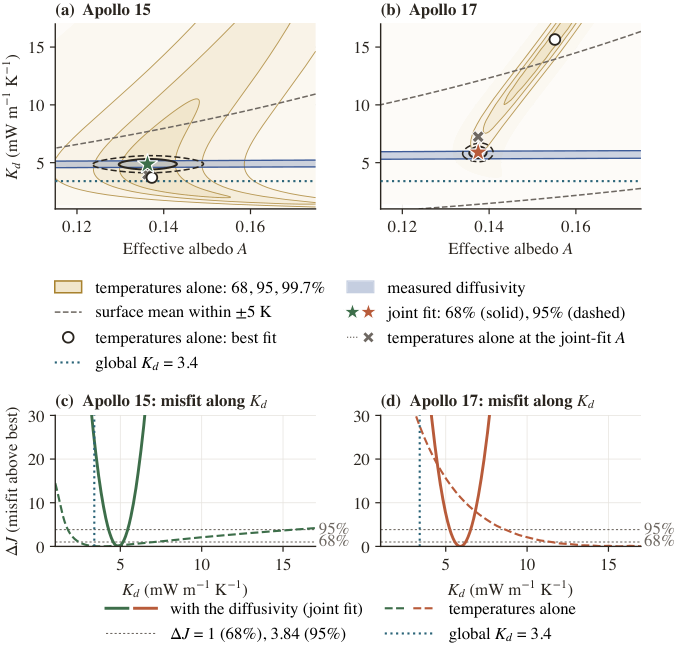

In [38]:
nb.show("fig_joint_constraints")

**The annual wave alone** (SI Figure S5, SI Table S11). Measured again at every
sensor in the full record; modeled with the real sunlight of 1966–1977, with a
free size and timing factor per probe.

In [39]:
aw = R["annual_wave"]["sites"]
st = R["annual_wave_surface_test"]["sites"]
display(pd.DataFrame({s: {v: round(aw[s]["variants"][v]["kd_mW"], 2) for v in aw[s]["variants"]} for s in S2})
        .rename_axis("annual-wave variant: K_d"))
unif = [aw[s]["uniform_kappa"][p]["amplitude"]["kappa"] for s in S2 for p in ("p1", "p2")]
scale = [st[s]["nominal"]["factor_at_best"][p]["scale"] for s in S2 for p in ("p1", "p2")]
lag = [abs(aw[s]["factors"][p]["phase_deg"]) / 360 * R["annual_wave"]["meta"]["year_days"] for s in S2 for p in ("p1", "p2")]   # the adopted fit
chk = nb.Checks("Section 3.3, the annual wave:")
chk.add("diffusivities from our amplitudes, uniform medium: within ... of Langseth et al. (1976)",
        max(abs(u - o[2]) for u, o in zip(unif, [o for s in S2 for o in JF["meta"]["kappa_obs_langseth1976_table1"][s]])), "0.06", ".2f")
chk.add_text("timing at the shallowest sensors right to within (days)", f"{nb.rounded(min(lag), '.0f')}-{nb.rounded(max(lag), '.0f')}", "2-12")
chk.add_text("the model wave is too large by a factor", nb.span([1 / x for x in scale], ".1f"), "1.5-2.5")
for s, (kd, lo, hi, dc) in (("A15", ("5.7", "5.3", "6.1", "190")), ("A17", ("5.6", "5.2", "6.1", "130"))):
    n = aw[s]["variants"]["nominal"]
    chk.add(f"{s}: K_d", n["kd_mW"], kd, ".1f")
for v, val in (("amplitude_only", "5.6"), ("phase_only", "5.9"), ("langseth_pairs_amp", "4.8")):
    chk.add(f"A15: {v.replace('_', ' ')}", aw["A15"]["variants"][v]["kd_mW"], val, ".1f")
chk.show()

,A15,A17
annual-wave variant: K_d,,
nominal,5.68,5.60
common_window,5.61,5.59
deg2,5.65,5.26
deg4,5.72,5.27
start_365,5.84,5.45
albedo_minus,5.69,5.59
albedo_plus,5.70,5.62
shared_factor,5.70,5.74
family_factor,5.76,4.79


Section 3.3, the annual wave:


quantity,this repository,paper,match
"diffusivities from our amplitudes, uniform medium: within ... of Langseth et al. (1976)",0.06,0.06,✓
timing at the shallowest sensors right to within (days),2-12,2-12,✓
the model wave is too large by a factor,1.5-2.5,1.5-2.5,✓
A15: K_d,5.7,5.7,✓
A17: K_d,5.6,5.6,✓
A15: amplitude only,5.6,5.6,✓
A15: phase only,5.9,5.9,✓
A15: langseth pairs amp,4.8,4.8,✓


All values match the paper.


True

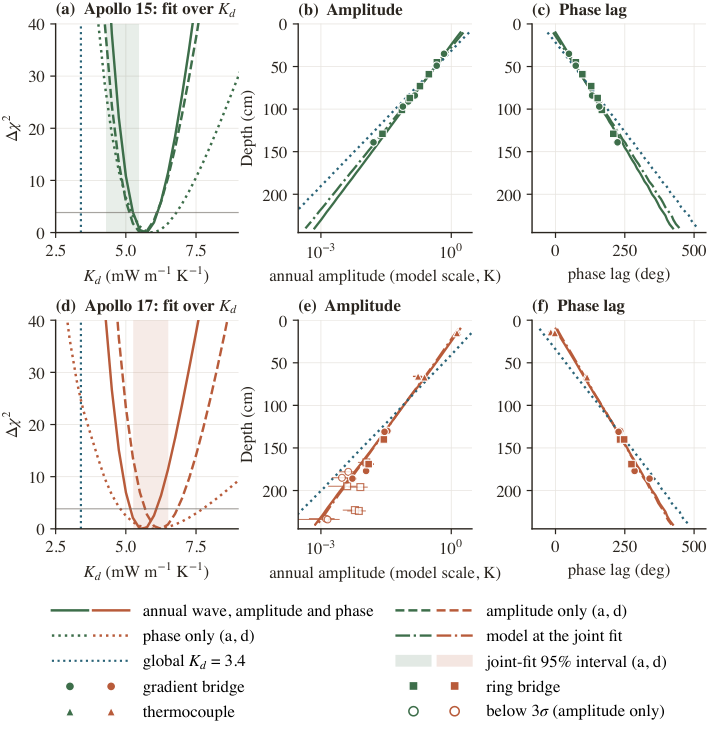

In [40]:
nb.show("fig_joint_annual_wave")

## Sections 3.4, 3.5: the two sites and the checks (SI Figures S6, S7; SI Tables S5, S6, S12, S13)
Every choice and input changed in turn.

In [41]:
sens = R["joint_fit_sensitivities"]["sites"]
rean = {s: [v["with_diffusivity"]["kd_star_mW"] if "with_diffusivity" in v else v["kd_star_mW"]
            for k, v in sens[s]["reanalysis"].items() if not k.startswith("zb_")] for s in S2}
cut = [abs((sens[s]["reanalysis"][k]["with_diffusivity"] if "with_diffusivity" in sens[s]["reanalysis"][k]
            else sens[s]["reanalysis"][k])["kd_star_mW"] - best[s]["kd_star_mW"]) for s in S2 for k in ("zb_70", "zb_90")]
record = [abs(v - best[s]["kd_star_mW"]) for s in S2 for v in rean[s] + [FC[s][f"drift_forward_{t}yr"]["kd_mW"] for t in (1, 2)]]
warm = max(abs(c["surface_as_measured"]["d_kd_mW"]) for s in S2 for k, c in R["transient_warming"]["sites"][s]["cases"].items()
           if k == "step_1.6K" or s == "A15")
chk = nb.Checks("Section 3.5, the sensors and the record:")
chk.add("deepest sensor held out, both sites: predicted to within (K)", max(abs(FC[s]["holdout_deepest"]["residual_K"]) for s in S2), "0.3", ".1f")
chk.add("cut, windows, 1-2 yr ahead, warming removed: K_d moves by at most", max(max(cut), max(record), warm), "0.06", ".2f")
chk.add("cut at 70 or 90 cm: K_d moves by at most (Section 3.5)", max(cut), "0.01", ".2f")
thr = [abs((v["with_diffusivity"] if "with_diffusivity" in v else v)["kd_star_mW"] - best[s]["kd_star_mW"]) for s in S2 for k, v in sens[s]["reanalysis"].items() if k.startswith("thr_")]
wch = [abs((v["with_diffusivity"] if "with_diffusivity" in v else v)["kd_star_mW"] - best[s]["kd_star_mW"]) for s in S2 for k, v in sens[s]["reanalysis"].items() if k.startswith(("floor_", "fallback_"))]
_thr = [float(k[4:]) for k in sens["A15"]["reanalysis"] if k.startswith("thr_")]
chk.add_text("thresholds tried (K/yr; Section 3.5)", f'{nb.rounded(min(_thr), ".2f")}-{nb.rounded(max(_thr), ".2f")}', "0.04-0.37")
chk.add("thresholds 0.04-0.37 K/yr and the window starts: K_d moves by at most (Section 3.5)", max(thr + wch), "0.01", ".2f")
win_len = [(np.datetime64(r["window_end"][:10]) - np.datetime64(r["window_start"][:10])).astype(int) / 365.25 for s in S2 for r in R["stability_windows"][s] if r["used"] and not r["method"].startswith("fallback")]
chk.add("windows that pass the threshold: median length, about (yr)", float(np.median(win_len)), "1", ".0f")
chk.add("0.08 K/yr over that length: change below about (K)", 0.08 * float(np.median(win_len)), "0.1", ".1f")
lk, fj = FC["A15"]["surface_mean_langseth1977"], FC["A15"]["fit_with_diffusivity"]   # Langseth & Keihm (1977), Table 1
chk.add("A15: mean surface temperature of the final report (K)", lk["surface_mean_obs_K"], "207", ".0f")
chk.add("A15 with 207 K: K_d* changes by", abs(lk["kd_mW"] - fj["kd_mW"]), "0.01", ".2f")
chk.add("A15 with 207 K: albedo changes by less than", abs(lk["A"] - fj["A"]), "<0.001")
chk.add("A15 with 207 K: modeled surface mean above the measured one (K)", lk["surface_mean_model_K"] - lk["surface_mean_obs_K"], "6.5", ".1f")
chk.show()

Section 3.5, the sensors and the record:


quantity,this repository,paper,match
"deepest sensor held out, both sites: predicted to within (K)",0.3,0.3,✓
"cut, windows, 1-2 yr ahead, warming removed: K_d moves by at most",0.06,0.06,✓
cut at 70 or 90 cm: K_d moves by at most (Section 3.5),0.01,0.01,✓
thresholds tried (K/yr; Section 3.5),0.04-0.37,0.04-0.37,✓
thresholds 0.04-0.37 K/yr and the window starts: K_d moves by at most (Section 3.5),0.01,0.01,✓
"windows that pass the threshold: median length, about (yr)",1,1,✓
0.08 K/yr over that length: change below about (K),0.1,0.1,✓
A15: mean surface temperature of the final report (K),207,207,✓
A15 with 207 K: K_d* changes by,0.01,0.01,✓
A15 with 207 K: albedo changes by less than,0.00016,<0.001,✓


All values match the paper.


True

In [42]:
eb = R["joint_fit_sensitivities"]["error_budget"]
keys = ["sigma_stat", "sigma_solver", "sigma_Qb", "sigma_rho", "sigma_cp", "sigma_Ks",
        "sigma_zb", "sigma_thr", "sigma_window", "sigma_epoch", "total_quadrature"]
display(pd.DataFrame({s: [round(eb[s][k], 4) for k in keys] for s in S2}, index=keys).rename_axis("SI Table S5 (mW m^-1 K^-1)"))
cd = R["joint_chi_density"]["sites"]
chk = nb.Checks("SI Table S5, error budget:")
P = {"A15": ("0.30", "<0.05", "<0.05", "0.40", "0.15", "<0.05", "0.52", "0.45"),
     "A17": ("0.33", "<0.05", "0.15", "0.51", "0.15", "<0.05", "0.64", "0.55")}
for s in S2:
    e, p = eb[s], P[s]
    for (lab, key), val in zip((("statistical", "sigma_stat"), ("solver", "sigma_solver"), ("Q_b", "sigma_Qb"),
                                ("density", "sigma_rho"), ("c_p", "sigma_cp"), ("K_s", "sigma_Ks")), p[:6]):
        chk.add(f"{s}: {lab}", e[key], val, ".2f")
    for key in ("sigma_zb", "sigma_thr", "sigma_window", "sigma_epoch"):
        chk.add(f"{s}: {key.split('_')[1]}", e[key], "<0.05")
    chk.add(f"{s}: total (quadrature)", e["total_quadrature"], p[6], ".2f")
    chk.add(f"{s}: chi 2.2-3.2 (half range)", abs(cd[s]["chi_2.2"]["kd_star_mW"] - cd[s]["chi_3.2"]["kd_star_mW"]) / 2, p[7], ".2f")
    chk.add(f"{s}: H 3-10 cm", e["conditional"]["H"], "<0.05")
    chk.add(f"{s}: albedo form", max(abs(v - e["kd_star_mW"]) for v in e["conditional"]["albedo_form_kd_mW"].values()), "<0.05")
qb = {s: max(abs(v["with_diffusivity"]["kd_star_mW"] - best[s]["kd_star_mW"]) for k, v in sens[s]["variants"].items() if k.startswith("Qb_")) for s in S2}
chk.add("A15: basal flux 14-25 mW m^-2 moves K_d by at most (SI Table S12)", qb["A15"], "0.01", ".2f")
chk.add("basal flux, both sites: K_d moves by at most (Section 3.5)", max(qb.values()), "0.25", ".2f")
for s, tot in (("A15", "0.5"), ("A17", "0.6")):
    chk.add(f"{s}: total uncertainty as printed in Section 3.5", eb[s]["total_quadrature"], tot, ".1f")
chk.show()

,A15,A17
SI Table S5 (mW m^-1 K^-1),,
sigma_stat,0.2957,0.3295
sigma_solver,0.0002,0.0024
sigma_Qb,0.0062,0.1475
sigma_rho,0.3990,0.5063
sigma_cp,0.1452,0.1533
sigma_Ks,0.0017,0.0081
sigma_zb,0.0060,0.0000
sigma_thr,0.0037,0.0027
sigma_window,0.0037,0.0072


SI Table S5, error budget:


quantity,this repository,paper,match
A15: statistical,0.30,0.30,✓
A15: solver,0.00025,<0.05,✓
A15: Q_b,0.0062,<0.05,✓
A15: density,0.40,0.40,✓
A15: c_p,0.15,0.15,✓
A15: K_s,0.0017,<0.05,✓
A15: zb,0.006,<0.05,✓
A15: thr,0.0037,<0.05,✓
A15: window,0.0037,<0.05,✓
A15: epoch,0.0025,<0.05,✓


All values match the paper.


True

In [43]:
mc = R["joint_mcmc"]
od = R["own_diffusivity_fit"]["variants"]
own = [v for v in od if v != "langseth1976"]
chk = nb.Checks("Sections 3.4, 3.5, the posterior and our own diffusivities:")
chk.add("our own diffusivities: largest p of the global value (still rejected)", max(od[v][s]["global_3p4"]["p"] for v in own for s in S2), "<1e-6")
chk.show()

Sections 3.4, 3.5, the posterior and our own diffusivities:


quantity,this repository,paper,match
our own diffusivities: largest p of the global value (still rejected),6.3e-07,<1e-6,✓


All values match the paper.


True

**Every variant that uses the annual wave gives 4.5–6.6** (SI Figure S7). The rows
of SI Figure S7 are read from the results files by `make_joint_figures.variant_rows`.

In [44]:
import sys
for p in ("pipeline/figures", "pipeline/compute", "."):
    if str(nb.CODE / p) not in sys.path:
        sys.path.insert(0, str(nb.CODE / p))
import make_joint_figures as mj
rows = mj.variant_rows(JF, FC, R["joint_fit_sensitivities"])
annual = [r for r in rows if r[0] != "One measurement at a time" or r[1].startswith("Annual wave")]
vals = [x for r in annual for s in S2 for x in ([r[2][s]["best"]] if r[2][s]["best"] is not None else []) + r[2][s]["pts"]]
display(pd.DataFrame([(g, lab, *(f'{d[s]["best"]:.2f}' if d[s]["best"] is not None else nb.span(d[s]["pts"], ".2f") for s in S2))
                      for g, lab, d in rows], columns=["group", "variant", "A15", "A17"]))
chk = nb.Checks("Section 3.5, SI Figure S7 (and key point 3, abstract, Conclusions):")
chk.add_text("every variant that uses the annual wave", nb.span(vals, ".1f"), "4.5-6.6")
chk.add_text("key point 3: most variants give about 5-6 (4.75-6.25), share above 90% at each site",
             str(all(np.mean([(v >= 4.75) & (v <= 6.25) for g, lab, d in annual for v in ([d[s]["best"]] if d[s]["best"] is not None else []) + list(d[s]["pts"])]) > 0.9 for s in S2)), "True")
chk.show()

,group,variant,A15,A17
0,Subsets of the sensors,Each probe,4.46-5.47,5.67-6.24
1,Subsets of the sensors,Each thermometer type,4.86-4.87,5.78-5.80
2,All sensors together,Joint fit,4.87,5.89
3,All sensors together,"MCMC, heat flow and density free",4.85,5.94
4,All sensors together,Our annual-wave diffusivities,4.89-6.13,5.76-6.09
5,One measurement at a time,Albedo fixed at 0.12,4.64,5.78
6,One measurement at a time,"Albedo fixed, 0.08 to 0.16",2.87-15.94,5.63-18.27
7,One measurement at a time,Temperatures alone,3.72,15.66
8,One measurement at a time,Annual wave alone,5.68,5.60
9,Other checks,Record reduction,4.86-4.88,5.83-5.93


Section 3.5, SI Figure S7 (and key point 3, abstract, Conclusions):


quantity,this repository,paper,match
every variant that uses the annual wave,4.5-6.6,4.5-6.6,✓
"key point 3: most variants give about 5-6 (4.75-6.25), share above 90% at each site",True,True,✓


All values match the paper.


True

**SI Figure S6** (the posterior) and **SI Figure S7** ($K_d$ from every variant).

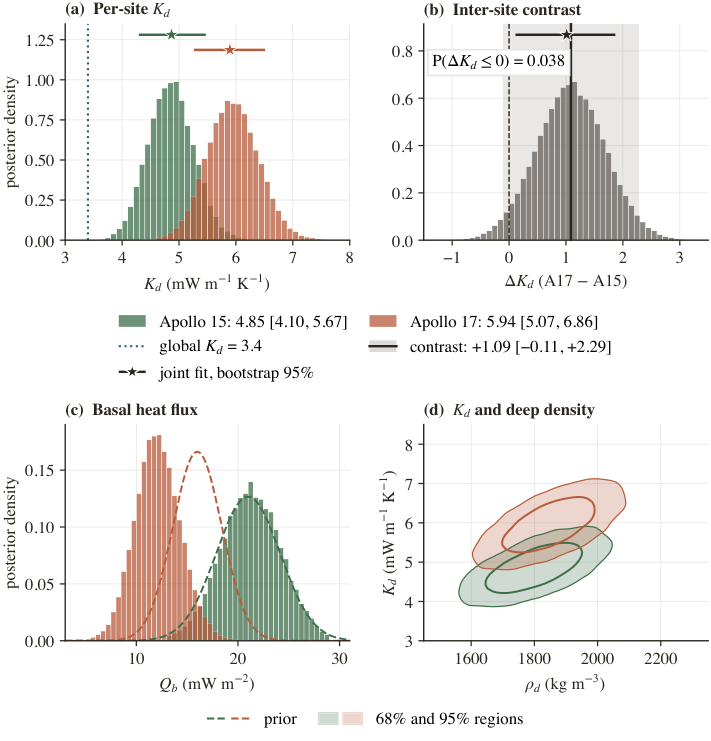

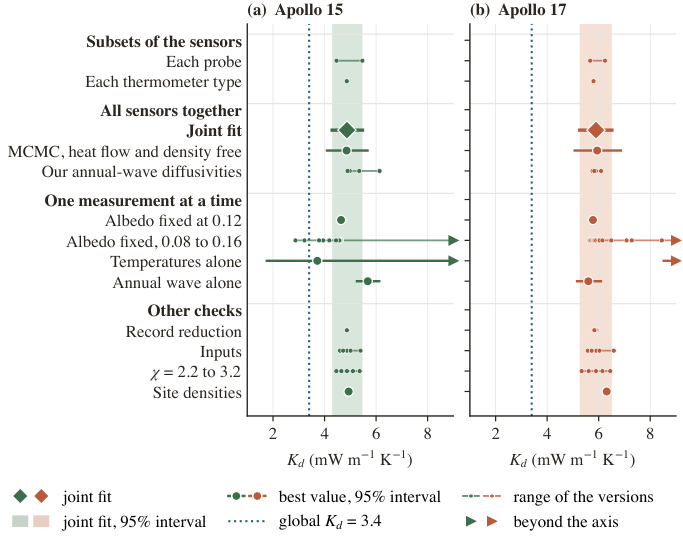

In [45]:
for f in ("fig_joint_mcmc", "fig_joint_variants"):
    nb.show(f)

## Section 4: discussion
What the values mean (4.1), whether the two sites differ (4.2) and what limits
the values (4.3).

In [46]:
jc = R["joint_mcmc"]["contrast_mW"]
ct = JF["contrast"]["with_diffusivity"]
po = LR["pooled"]
pc = R["joint_probe_checks"]["sites"]
awc = {v: aw["A17"]["variants"][v]["kd_mW"] - aw["A15"]["variants"][v]["kd_mW"] for v in aw["A15"]["variants"]}
chk = nb.Checks("Sections 4.1, 4.2:")
chk.add("A15: effective conductivity at the sensors", FC["A15"]["effective_conductivity_mW"]["mean"], "9.8", ".1f")
chk.add("A17: effective conductivity at the sensors", FC["A17"]["effective_conductivity_mW"]["mean"], "12.1", ".1f")
from lunar.properties import conductivity_hayne, conductivity_martinez, density_hayne
keff_glob, keff_ms, ratios = {}, {}, []
for s in S2:
    o = extract_sensor_stability(SITES[s]["mission"], min_depth_cm=SITES[s]["MIN_DEPTH_CM"])
    mk = np.asarray(o["deep_mask"], bool); zz = np.asarray(o["depth_cm_all"])[mk] / 100; TT = np.asarray(o["T_eq_all"])[mk]
    keff_glob[s] = conductivity_hayne(TT, zz, Ks=HAYNE["K_S"], Kd=3.4e-3, H=HAYNE["H"], chi=HAYNE["CHI"]).mean() * 1e3
    keff_ms[s] = conductivity_martinez(TT, rho=density_hayne(zz)).mean() * 1e3
    ke = FC[s]["effective_conductivity_mW"]["mean"]
    ratios += [ke / keff_glob[s], ke / keff_ms[s]]
for s in S2:
    chk.add(f"{s}: effective conductivity of the global value at the sensors", keff_glob[s], "7", ".0f")
    chk.add(f"{s}: effective conductivity of Martinez & Siegler at the sensors", keff_ms[s], "8", ".0f")
chk.add_text("Apollo regolith conducts better than the global models by a factor", nb.span(ratios, ".1f"), "1.2-1.7")
ko = JF["meta"]["kappa_obs_langseth1976_table1"]
chk.add("published diffusivities: A17 higher than A15 by (%)",
        100 * (sum(x[2] for x in ko["A17"]) / sum(x[2] for x in ko["A15"]) - 1), "17", ".0f")
chk.add("A17 - A15, bootstrap median", ct["median"], "+1.0", "+.1f")
chk.add("   95% lower", ct["p2_5"], "+0.1", "+.1f")
chk.add("   95% upper", ct["p97_5"], "+1.9", "+.1f")
chk.add("pooled: one shared K_d", po["kd_shared_mW"], "5.3", ".1f")
chk.add("pooled: shared, p", po["shared_vs_per_site"]["p"], "0.02", ".2f")
chk.add("A17 - A15, posterior median", jc["p50"], "+1.1", "+.1f")
chk.add("   95% lower", jc["p2.5"], "-0.1", "+.1f")
chk.add("   95% upper", jc["p97.5"], "+2.3", "+.1f")
chk.add_text("K_d from the transient diffusivities, both sites", nb.span(list(pc["A15"]["transient_kd_range_mW"]) + list(pc["A17"]["transient_kd_range_mW"]), ".1f"), "3.7-4.5")
chk.add("annual wave: the two sites agree to within", abs(awc["nominal"]), "0.1", ".1f")
chk.show()

Sections 4.1, 4.2:


quantity,this repository,paper,match
A15: effective conductivity at the sensors,9.8,9.8,✓
A17: effective conductivity at the sensors,12.1,12.1,✓
A15: effective conductivity of the global value at the sensors,7,7,✓
A15: effective conductivity of Martinez & Siegler at the sensors,8,8,✓
A17: effective conductivity of the global value at the sensors,7,7,✓
A17: effective conductivity of Martinez & Siegler at the sensors,8,8,✓
Apollo regolith conducts better than the global models by a factor,1.2-1.7,1.2-1.7,✓
published diffusivities: A17 higher than A15 by (%),17,17,✓
"A17 - A15, bootstrap median",+1.0,+1.0,✓
95% lower,+0.1,+0.1,✓


All values match the paper.


True

In [47]:
chis = ("chi_2.2", "chi_2.45", "chi_2.95", "chi_3.2")
gl = LR["sites"]
mq = R["joint_mcmc"]["A17"]["posterior"]["Qb_mW"]
amp = {p: aw["A15"]["uniform_kappa"][p] for p in ("p1", "p2")}
surf = R["annual_wave_surface_test"]["sites"]
twc = R["transient_warming"]["sites"]
chk = nb.Checks("Section 4.3:")
for s in S2:
    chk.add(f"{s}: chi 2.2-3.2 moves K_d* by about +- (%, half range)",
            100 * abs(cd[s]["chi_2.2"]["kd_star_mW"] - cd[s]["chi_3.2"]["kd_star_mW"]) / 2 / best[s]["kd_star_mW"], "9", ".0f")
from lunar.properties import conductivity_hayne as _kh
def _keff(s, kd_mW, chi):   # effective conductivity at the mean sensor temperature (as in SI Table S14)
    o = extract_sensor_stability(SITES[s]["mission"], min_depth_cm=SITES[s]["MIN_DEPTH_CM"])
    T = np.asarray(o["T_eq_all"])[np.asarray(o["deep_mask"], bool)]
    return float(_kh(np.array([T.mean()]), np.array([5.0]), Ks=HAYNE["K_S"], Kd=kd_mW * 1e-3, H=HAYNE["H"], chi=chi)[0] * 1e3)
dke = max(abs(_keff(s, cd[s][c]["kd_star_mW"], float(c.split("_")[1])) - _keff(s, best[s]["kd_star_mW"], HAYNE["CHI"])) for s in S2 for c in chis)
chk.add("chi 2.2-3.2: effective conductivity the same to within (mW m^-1 K^-1; Conclusions)", dke, "0.1", ".1f")
chk.add("global value rejected at every chi 2.2-3.2: largest p", max(gl[s]["global_3p4_chi_density"][c]["p"] for s in S2 for c in chis), "<1e-3")
chk.add_text("chi = 1.5: albedo at the edge (no physical albedo fits)", str(all(cd[s]["chi_1.5"]["A"] <= 0.0 for s in S2)), "True")
_rs = R["joint_chi_density"]["meta"]["rho_site"]
chk.add("A15: Langseth (1976) density, midpoint of 1750-1900 (kg m^-3; Sec. 4.1)", _rs["A15"], "1825", ".0f")
chk.add("A17: Langseth (1976) density, midpoint of 1830-2090 (kg m^-3; Sec. 4.1)", _rs["A17"], "1960", ".0f")
chk.add_text("both above the 1800 kg m^-3 of the models", str(min(_rs.values()) > 1800), "True")
_mdf = nb.load("martinez_diffusivity.json")["sites"]    # density alone, in the Martinez & Siegler model
chk.add("A15: Martinez & Siegler deep density giving the measured diffusivities, about (kg m^-3, nearest 10; Sec. 4.1)", round(_mdf["A15"]["rho_d_for_mean_obs_kg_m3"] / 10) * 10, "2260", ".0f")
chk.add("A17: Martinez & Siegler deep density giving the measured diffusivities, about (kg m^-3, nearest 10; Sec. 4.1)", round(_mdf["A17"]["rho_d_for_mean_obs_kg_m3"] / 10) * 10, "2840", ".0f")
chk.add_text("both above the 1990 kg m^-3 top of the drill cores (Carrier 1991)", str(min(_mdf[s]["rho_d_for_mean_obs_kg_m3"] for s in S2) > 1990), "True")
chk.add_text("and above the tops of the Langseth (1976) ranges, 1900 and 2090", str(_mdf["A15"]["rho_d_for_mean_obs_kg_m3"] > 1900 and _mdf["A17"]["rho_d_for_mean_obs_kg_m3"] > 2090), "True")
chk.add("A15: measured site density, K_d*", cd["A15"]["rho_site"]["kd_star_mW"], "4.9", ".1f")
_js = R["joint_fit_sensitivities"]                  # K_d* is proportional to the density: where would it be 3.4?
_kr = [[_js["sites"][_s]["variants"]["rho_d_1700"]["with_diffusivity"]["kd_star_mW"] / 1700, _js["error_budget"][_s]["kd_star_mW"] / 1800,
        _js["sites"][_s]["variants"]["rho_d_2000"]["with_diffusivity"]["kd_star_mW"] / 2000] for _s in S2]
chk.add("K_d* proportional to the density: K_d*/rho varies by at most (%, 1700-2000 kg m^-3, both sites; Sec. 4.3)",
        max(100 * (max(k) / min(k) - 1) for k in _kr), "<1")
for _s, _paper in (("A15", "1250"), ("A17", "1060")):
    _pts = np.array([(1700, _js["sites"][_s]["variants"]["rho_d_1700"]["with_diffusivity"]["kd_star_mW"]),
                     (1800, _js["error_budget"][_s]["kd_star_mW"]),
                     (2000, _js["sites"][_s]["variants"]["rho_d_2000"]["with_diffusivity"]["kd_star_mW"])])
    _m, _b = np.polyfit(_pts[:, 0], _pts[:, 1], 1)
    chk.add(f"{_s}: density at which K_d* = 3.4, about (kg m^-3, nearest 10)", round((3.4 - _b) / _m / 10) * 10, _paper, ".0f")
chk.add("A17: measured site density, K_d*", cd["A17"]["rho_site"]["kd_star_mW"], "6.3", ".1f")
md = nb.load("martinez_density_fit.json")["sites"]
chk.add("   misfit at the best density, A15 (K; SI Table S4)", md["A15"]["best"]["rmse_K"], "0.90", ".2f")
chk.add("   misfit at the best density, A17 (K; SI Table S4)", md["A17"]["best"]["rmse_K"], "0.61", ".2f")
ob17 = GE["sites"]["A17"]["observed"]
chk.add("A17 posterior basal flow, median: about (mW m^-2)", mq["p50"], "12", ".0f")
_jb = R["joint_albedo_fit"]["sites"]                 # K_d with Q_b free (posterior median) against the joint fit
chk.add("   while K_d moves by less than (posterior median against the joint fit, both sites)",
        max(abs(R["joint_mcmc"][s]["posterior"]["kd_mW"]["p50"] - _jb[s]["with_diffusivity"]["best"]["kd_star_mW"]) for s in S2), "<0.05")
chk.add("   close to what the drill-core gradient requires (mW m^-2)", ob17["thermoluminescence"]["qb_matching_mW"], "12", ".0f")
chk.add_text("   and the 1974 gradients, common and translated epoch (mW m^-2)", nb.span([ob17["common_1974"]["qb_matching_mW"], ob17["translated_1974"]["qb_matching_mW"]], ".0f"), "9-10")
chk.add_text("A15: the delay implies a diffusivity higher than the fading does by (%)",
             nb.span([100 * (amp[p]["phase"]["kappa"] / amp[p]["amplitude"]["kappa"] - 1) for p in amp], ".0f"), "21-25")
chk.add("A17, a darkening twice as large (3.5 K step): K_d lower by", -twc["A17"]["cases"]["step_3.5K"]["surface_as_measured"]["d_kd_mW"], "0.45", ".2f")
chk.show()

Section 4.3:


quantity,this repository,paper,match
"A15: chi 2.2-3.2 moves K_d* by about +- (%, half range)",9,9,✓
"A17: chi 2.2-3.2 moves K_d* by about +- (%, half range)",9,9,✓
chi 2.2-3.2: effective conductivity the same to within (mW m^-1 K^-1; Conclusions),0.1,0.1,✓
global value rejected at every chi 2.2-3.2: largest p,0.00013,<1e-3,✓
chi = 1.5: albedo at the edge (no physical albedo fits),True,True,✓
"A15: Langseth (1976) density, midpoint of 1750-1900 (kg m^-3; Sec. 4.1)",1825,1825,✓
"A17: Langseth (1976) density, midpoint of 1830-2090 (kg m^-3; Sec. 4.1)",1960,1960,✓
both above the 1800 kg m^-3 of the models,True,True,✓
"A15: Martinez & Siegler deep density giving the measured diffusivities, about (kg m^-3, nearest 10; Sec. 4.1)",2260,2260,✓
"A17: Martinez & Siegler deep density giving the measured diffusivities, about (kg m^-3, nearest 10; Sec. 4.1)",2840,2840,✓


All values match the paper.


True

---
# 5. The Supporting Information, table by table

Every number printed in the 14 tables of the Supporting Information, cell by
cell, next to the value in `code/results/` rounded the way the SI rounds it.
The printed values are typed in below as they appear in the SI.

In [48]:
for n in ("martinez_density_fit", "joint_diviner", "cpp_benchmark", "joint_numerics_certification"):
    R.setdefault(n, nb.load(f"{n}.json"))
def sg(v, fmt=".2f"):
    """Signed as the SI prints it: +1.35, -0.02, and 0.00 (no sign) when it rounds to zero."""
    s = nb.rounded(v, fmt)
    return s if float(s) == 0 or s.startswith("-") else "+" + s
def cells(chk, label, names, shown, paper):
    """One check per printed cell."""
    assert len(names) == len(shown) == len(paper), label
    for n, a, b in zip(names, shown, paper):
        chk.add_text(f"{label}: {n}", a, b)

**SI Table S1, stability windows** (`stability_windows.json`).

In [49]:
S1 = """
A15 1 TG11B 84 fallback 1975-05-01 1975-06-30 11579 253.20 0.05 +0.13
A15 2 TR22B 87 fallback 1973-12-12 1974-12-27 153 250.88 0.09 +0.19
A15 1 TG12A 91 strict 1974-04-09 1975-06-30 20883 253.15 0.04 +0.03
A15 2 TG22B 97 strict 1974-05-11 1975-06-30 20432 251.16 0.05 +0.08
A15 1 TR12A 101 fallback 1973-12-03 1974-12-27 153 253.14 0.07 +0.22
A15 1 TR12B 129 fallback 1973-12-03 1974-12-27 153 253.36 0.06 +0.19
A15 1 TG12B 139 strict 1974-04-09 1975-06-30 20883 253.53 0.03 +0.07
A17 1 TG11A 130 fallback 1977-05-21 1977-09-30 23969 256.48 0.04 +0.32
A17 2 TG21A 131 fallback 1977-05-21 1977-09-30 23917 256.59 0.04 +0.22
A17 1 TR11A 140 fallback 1974-06-03 1974-12-27 79 255.67 0.08 +0.47
A17 2 TR21A 140 fallback 1974-06-05 1974-12-27 79 256.24 0.04 +0.23
A17 1 TR11B 167 fallback 1974-06-03 1974-12-27 79 255.88 0.06 +0.33
A17 2 TR21B 169 fallback 1974-06-05 1974-12-27 79 256.38 0.03 +0.15
A17 1 TG11B 177 fallback 1977-05-21 1977-09-30 23969 256.60 0.03 +0.22
A17 2 TG21B 178 fallback 1977-05-21 1977-09-30 23917 256.74 0.03 +0.11
A17 1 TG12A 185 fallback 1974-05-28 1974-12-31 5148 256.06 0.05 +0.22
A17 2 TG22A 186 strict 1973-12-18 1974-12-31 9239 256.52 0.03 +0.06
A17 1 TR12A 195 fallback 1974-05-24 1974-12-27 82 256.13 0.04 +0.18
A17 2 TR22A 196 strict 1974-01-02 1974-12-27 141 256.55 0.02 +0.06
A17 1 TR12B 223 strict 1973-12-14 1974-12-27 147 256.38 0.03 +0.07
A17 2 TR22B 224 strict 1974-01-02 1974-12-27 141 256.74 0.02 +0.03
A17 1 TG12B 233 strict 1973-12-18 1974-12-31 9267 256.48 0.03 +0.06
A17 2 TG22B 234 strict 1973-12-18 1974-12-31 9239 256.84 0.03 +0.01"""
chk = nb.Checks("SI Table S1, stability windows:")
used = {s: [r for r in R["stability_windows"][s] if r["used"]] for s in S2}
printed = [l.split() for l in S1.strip().splitlines()]
for s in S2:   # the table lists every used sensor, by depth
    chk.add_text(f"{s}: sensors listed, in depth order", " ".join(r["sensor"] for r in sorted(used[s], key=lambda r: r["depth_cm"])),
                 " ".join(p[2] for p in printed if p[0] == s))
for p in printed:
    r = next(r for r in used[p[0]] if r["sensor"] == p[2])
    crit = {"trend_flat": "strict", "fallback_last25": "fallback"}[r["method"]]
    cells(chk, f"{p[0]} {p[2]}", ["probe", "depth", "criterion", "first date", "last date", "N", "T_eq", "sigma", "slope"],
          [str(r["probe"]), f'{r["depth_cm"]:.0f}', crit, r["window_start"], r["window_end"], str(r["n_samples"]),
           nb.rounded(r["T_eq_K"], ".2f"), nb.rounded(r["T_std_K"], ".2f"), sg(r["trailing_slope_K_per_yr"])], p[1:2] + p[3:])
chk.show()

SI Table S1, stability windows:


quantity,this repository,paper,match
"A15: sensors listed, in depth order",TG11B TR22B TG12A TG22B TR12A TR12B TG12B,TG11B TR22B TG12A TG22B TR12A TR12B TG12B,✓
"A17: sensors listed, in depth order",TG11A TG21A TR11A TR21A TR11B TR21B TG11B TG21B TG12A TG22A TR12A TR22A TR12B TR22B TG12B TG22B,TG11A TG21A TR11A TR21A TR11B TR21B TG11B TG21B TG12A TG22A TR12A TR22A TR12B TR22B TG12B TG22B,✓
A15 TG11B: probe,1,1,✓
A15 TG11B: depth,84,84,✓
A15 TG11B: criterion,fallback,fallback,✓
A15 TG11B: first date,1975-05-01,1975-05-01,✓
A15 TG11B: last date,1975-06-30,1975-06-30,✓
A15 TG11B: N,11579,11579,✓
A15 TG11B: T_eq,253.20,253.20,✓
A15 TG11B: sigma,0.05,0.05,✓


All values match the paper.


True

**SI Table S2, measured and modeled gradients** (`gradient_epochs.json`).

In [50]:
chk = nb.Checks("SI Table S2, gradients:")
G = R["gradient_epochs"]["sites"]
for key, a15, a17, qb in (("certified", ("2.54", "2.02"), ("0.37", "0.23"), "3.6"),
                          ("common_1974", ("2.63", "1.99"), ("0.81", "0.20"), "9.5"),
                          ("translated_1974", ("2.59", "2.00"), ("0.89", "0.18"), "10.5"),
                          ("thermoluminescence", None, ("1.0", "0.5"), "12.0")):
    for s, pr in (("A15", a15), ("A17", a17)):
        if pr is None:
            continue
        o = G[s]["observed"][key]; f = ".1f" if key == "thermoluminescence" else ".2f"
        cells(chk, f"{key}, {s}", ["gradient", "standard error"], [nb.rounded(o["gradient_K_per_m"], f), nb.rounded(o["se"], f)], list(pr))
    chk.add(f"{key}: Q_b matching the A17 gradient", G["A17"]["observed"][key]["qb_matching_mW"], qb, ".1f")
for key, a15, a17 in (("joint_fit", "2.14", "1.32"), ("global_3p4", "3.06", "2.28"), ("martinez", "2.66", "1.99")):
    cells(chk, f"model, {key}", ["A15", "A17"], [nb.rounded(G[s]["model_gradient_K_per_m"][key], ".2f") for s in S2], [a15, a17])
chk.show()

SI Table S2, gradients:


quantity,this repository,paper,match
"certified, A15: gradient",2.54,2.54,✓
"certified, A15: standard error",2.02,2.02,✓
"certified, A17: gradient",0.37,0.37,✓
"certified, A17: standard error",0.23,0.23,✓
certified: Q_b matching the A17 gradient,3.6,3.6,✓
"common_1974, A15: gradient",2.63,2.63,✓
"common_1974, A15: standard error",1.99,1.99,✓
"common_1974, A17: gradient",0.81,0.81,✓
"common_1974, A17: standard error",0.20,0.20,✓
common_1974: Q_b matching the A17 gradient,9.5,9.5,✓


All values match the paper.


True

**SI Table S9, the ±5 K test of Hayne et al. (2017)** (`joint_probe_checks.json`).

In [51]:
S9 = {"A15": [("1.25", "209.6", "256.0", "yes"), ("3.4", "212.8", "253.4", "yes"), ("5.00", "214.5", "253.5", "yes"),
              ("6.50", "215.9", "253.8", "yes"), ("10.25", "218.7", "254.6", "no")],
      "A17": [("1.25", "211.7", "260.6", "yes"), ("3.4", "214.9", "257.2", "yes"), ("5.00", "216.7", "257.1", "yes"),
              ("6.50", "218.1", "257.3", "yes"), ("10.25", "220.9", "258.0", "yes")]}
chk = nb.Checks("SI Table S9, the +-5 K test at A = 0.12:")
for s in S2:
    kt = R["joint_probe_checks"]["sites"][s]["keihm_test_values_A_0.12"]
    chk.add(f"{s}: target surface mean", kt["surface_obs_K"], {"A15": "211", "A17": "216"}[s], ".0f")
    chk.add(f"{s}: target deep temperature", kt["deep_obs_K"], {"A15": "252", "A17": "256"}[s], ".0f")
    for r, p in zip(kt["rows"], S9[s]):
        kd = p[0]
        cells(chk, f"{s}, K_d {kd}", ["K_d", "surface mean", "deep temperature", "passes"],
              [nb.rounded(r["kd_mW"], ".1f" if kd == "3.4" else ".2f"), nb.rounded(r["surface_K"], ".1f"), nb.rounded(r["deep_K"], ".1f"),
               "yes" if r["passes"] else "no"], list(p))
for s, hi in (("A15", "6.5"), ("A17", "10.3")):
    k = R["joint_probe_checks"]["sites"][s]["keihm_test_A_0.12"]["kd_pass_mW"]
    cells(chk, f"{s}: every K_d that passes", ["from", "to"], [nb.rounded(k[0], ".1f"), nb.rounded(k[1], ".1f")], ["1.3", hi])
chk.show()

SI Table S9, the +-5 K test at A = 0.12:


quantity,this repository,paper,match
A15: target surface mean,211,211,✓
A15: target deep temperature,252,252,✓
"A15, K_d 1.25: K_d",1.25,1.25,✓
"A15, K_d 1.25: surface mean",209.6,209.6,✓
"A15, K_d 1.25: deep temperature",256.0,256.0,✓
"A15, K_d 1.25: passes",yes,yes,✓
"A15, K_d 3.4: K_d",3.4,3.4,✓
"A15, K_d 3.4: surface mean",212.8,212.8,✓
"A15, K_d 3.4: deep temperature",253.4,253.4,✓
"A15, K_d 3.4: passes",yes,yes,✓


All values match the paper.


True

**SI Table S10, the effect of the diffusivity at Apollo 17** (`joint_valley.json`).

In [52]:
S10 = [("3.4", "0.87", "0.57", "0.57", "-5.4", "-3.9", "+22.9", "+42.9", "+65.8"),
       ("5.0", "0.49", "0.83", "0.83", "-2.1", "-0.6", "+4.8", "+2.6", "+7.4"),
       ("6.0", "0.43", "1.00", "1.00", "0.0", "+1.5", "0.0", "0.0", "0.0"),
       ("7.0", "0.39", "1.16", "1.17", "+2.1", "+3.6", "-2.8", "+14.8", "+11.9"),
       ("8.0", "0.40", "1.33", "1.33", "+4.2", "+5.7", "-1.5", "+47.0", "+45.5"),
       ("10.0", "0.60", "1.67", "1.67", "+8.3", "+9.8", "+11.7", "+164.3", "+176.0")]
v = R["joint_valley"]["A17"]
chk = nb.Checks("SI Table S10, the diffusivity at Apollo 17:")
chk.add("albedo held at", v["A"], "0.137", ".3f")
for r, p in zip(v["rows"], S10):
    cells(chk, f"K_d {p[0]}", ["K_d", "RMSE", "kappa 1", "kappa 2", "misfit 1 (sigma)", "misfit 2 (sigma)", "dJ temperatures", "dJ diffusivity", "dJ"],
          [nb.rounded(r["kd_mW"], ".1f"), nb.rounded(r["sensor_rmse_K"], ".2f"), *(nb.rounded(k, ".2f") for k in r["kappa_model"]),
           *(sg(x, ".1f") for x in r["kappa_sigmas"]), sg(r["dJ_sensors"] + r["dJ_surface"], ".1f"),
           sg(r["dJ_diffusivity"], ".1f"), sg(r["dJ_total"], ".1f")], list(p))
chk.show()

SI Table S10, the diffusivity at Apollo 17:


quantity,this repository,paper,match
albedo held at,0.137,0.137,✓
K_d 3.4: K_d,3.4,3.4,✓
K_d 3.4: RMSE,0.87,0.87,✓
K_d 3.4: kappa 1,0.57,0.57,✓
K_d 3.4: kappa 2,0.57,0.57,✓
K_d 3.4: misfit 1 (sigma),-5.4,-5.4,✓
K_d 3.4: misfit 2 (sigma),-3.9,-3.9,✓
K_d 3.4: dJ temperatures,+22.9,+22.9,✓
K_d 3.4: dJ diffusivity,+42.9,+42.9,✓
K_d 3.4: dJ,+65.8,+65.8,✓


All values match the paper.


True

**SI Table S13, modeled minus Diviner surface temperatures** (`joint_diviner.json`).

In [53]:
S13 = {("A15", "hayne_joint"): "+2.6 +1.4 +3.9 +0.3 -1.9 +1.9", ("A15", "hayne_global_fittedA"): "+0.9 +1.3 +0.5 -1.7 -2.0 -1.5",
       ("A15", "martinez_forward_jointA"): "-0.2 +1.5 -2.0 -3.0 -1.7 -4.0",
       ("A17", "hayne_joint"): "+3.0 +0.6 +5.5 +0.1 -4.3 +3.4", ("A17", "hayne_global_fittedA"): "+0.1 +0.1 +0.1 -3.2 -4.8 -2.0",
       ("A17", "martinez_forward_jointA"): "-0.8 +0.8 -2.4 -4.3 -4.2 -4.4"}
chk = nb.Checks("SI Table S13, Diviner:")
for (s, m), p in S13.items():
    d = R["joint_diviner"][s]["models"][m]
    cells(chk, f"{s} {m}", ["zonal mean", "zonal day", "zonal night", "site mean", "site day", "site night"],
          [sg(d[w][k], ".1f") for w in ("zonal", "site_pm0.5deg") for k in ("bias_K", "bias_day_K", "bias_night_K")], p.split())
chk.show()

SI Table S13, Diviner:


quantity,this repository,paper,match
A15 hayne_joint: zonal mean,+2.6,+2.6,✓
A15 hayne_joint: zonal day,+1.4,+1.4,✓
A15 hayne_joint: zonal night,+3.9,+3.9,✓
A15 hayne_joint: site mean,+0.3,+0.3,✓
A15 hayne_joint: site day,-1.9,-1.9,✓
A15 hayne_joint: site night,+1.9,+1.9,✓
A15 hayne_global_fittedA: zonal mean,+0.9,+0.9,✓
A15 hayne_global_fittedA: zonal day,+1.3,+1.3,✓
A15 hayne_global_fittedA: zonal night,+0.5,+0.5,✓
A15 hayne_global_fittedA: site mean,-1.7,-1.7,✓


All values match the paper.


True

**SI Table S7, temperature-only fits with fixed or published albedos**
(`albedo_sensitivity.json`, `albedo_anchor.json`, `likelihood_ratio.json`).
$K_d$ at the grid edge prints as 27\*; † marks a treatment that matches both
measurements (bias within 1 K, surface mean within 5 K).

In [54]:
S7 = [  # treatment: A0, then K_d, bias, surface mean at A15 and at A17
    ("Constant, lunar average", "0.12", "4.64", "+1.35", "214.2", "5.78", "+1.47", "217.4"),
    ("Constant, site map", "0.109 / 0.095", "4.64", "+2.29", "214.8", "5.66", "+3.54", "218.7"),
    ("Hayne law, map, f=0.25", "0.109 / 0.095", "4.53†", "+0.22", "212.9", "5.74", "+1.68", "217.1"),
    ("Hayne law, map, f=0.5", "0.109 / 0.095", "15.33", "-0.02", "218.4", "8.61†", "+0.04", "217.6"),
    ("Hayne law, map, f=0.75", "0.109 / 0.095", "27*", "-0.35", "220.8", "20.09", "0.00", "221.8"),
    ("Hayne law, map, f=1", "0.109 / 0.095", "0.97", "-0.42", "201.4", "27*", "-1.09", "222.2"),
    ("Hayne law, lunar average, f=1", "0.12", "0.89", "-0.51", "200.6", "1.23", "-0.45", "203.8"),
    ("Feng et al. (2020) law, map", "0.086 / 0.076", "1.04", "-0.36", "202.5", "27*", "-0.62", "222.9"),
    ("Vasavada et al. (2012) law, map", "0.109 / 0.095", "27*", "-0.13", "221.1", "18.82", "0.00", "221.5"),
    ("Vasavada et al. (2012) law, mare", "0.07", "8.74†", "-0.04", "215.0", "6.82†", "+0.15", "216.0")]
cases = R["albedo_sensitivity"]["cases"]; laws = R["albedo_anchor"]["published_laws_at_sites"]
amap = {s: next(c["A0"] for c in cases if c["site"] == s and c["family"] == "angular") for s in S2}   # the map albedo
def law(s, start):
    return next(e for e in laws if e["site"] == s and e["label"].startswith(start))
def entry(s, i):
    if i == 0: return next(c for c in cases if c["site"] == s and c["family"] == "constant" and abs(c["A"] - 0.12) < 1e-9)
    if 1 <= i <= 5: return next(c for c in cases if c["site"] == s and c["family"] == "angular" and c["A0"] == amap[s] and c["f"] == (0, 0.25, 0.5, 0.75, 1.0)[i - 1])
    return law(s, ("Hayne 2017 standard", "Feng 2020 eq. 9, LOLA mean3x3", "Vasavada 2012 eq. 1, map A0 mean3x3", "Vasavada 2012 eq. 1, mare")[i - 6])
def a0(s, i, e):
    return e.get("A0", e.get("A"))
chk = nb.Checks("SI Table S7, fixed and published albedos:")
for i, p in enumerate(S7):
    e = {s: entry(s, i) for s in S2}
    A0 = [nb.rounded(a0(s, i, e[s]), ".3f").rstrip("0") if i in (0, 6, 9) else nb.rounded(a0(s, i, e[s]), ".3f") for s in S2]
    shown = [A0[0] if A0[0] == A0[1] else " / ".join(A0)]
    for s in S2:
        x = e[s]; tobs = {"A15": 211, "A17": 216}[s]
        mark = "†" if abs(x["bias_K"]) <= 1 and abs(x["surface_mean_K"] - tobs) <= 5 else ""
        kd = "27*" if x["at_grid_edge"] else nb.rounded(x["kd_star_mW"], ".2f") + mark
        shown += [kd, sg(x["bias_K"]), nb.rounded(x["surface_mean_K"], ".1f")]
    cells(chk, p[0], ["A0", "A15 K_d", "A15 bias", "A15 surface", "A17 K_d", "A17 bias", "A17 surface"], shown, list(p[1:]))
scan = {s: [c["kd_star_mW"] for c in cases if c["site"] == s and c["family"] == "constant" and 0.08 - 1e-9 <= c["A"] <= 0.16 + 1e-9] for s in S2}
cells(chk, "constant albedo 0.08-0.16", ["A15 from", "A15 to", "A17 from", "A17 to"],
      [nb.rounded(f(scan[s]), ".2f") for s in S2 for f in (min, max)], ["2.87", "15.94", "5.63", "18.27"])
adm = R["albedo_anchor"]["admissible_treatments"]; fx = {s: LR["sites"][s]["global_3p4_fixed_albedo_temperature_only"] for s in S2}
chk.add_text("A17: global gradient over the treatments that match both", nb.span(adm["A17"]["gradient_model_at_global"], ".2f"), "2.26-2.29")
chk.add_text("A17: Delta J of the global value over those treatments", nb.span(fx["A17"]["delta_J"], ".1f"), "14.1-38.2")
chk.add("A17: largest p", max(fx["A17"]["p"]), "<2e-4")
chk.add("A15: largest Delta J", max(fx["A15"]["delta_J"]), "1.4", ".1f")
sv = R["joint_fit_sensitivities"]["sites"]
chk.add("with the diffusivity, the angular laws within ... of the joint fit",
        max(abs(sv[s]["variants"][v]["with_diffusivity"]["kd_star_mW"] - best[s]["kd_star_mW"]) for s in S2 for v in ("form_vasavada2012", "form_hayne2017")), "0.03", ".2f")
chk.show()

SI Table S7, fixed and published albedos:


quantity,this repository,paper,match
"Constant, lunar average: A0",0.12,0.12,✓
"Constant, lunar average: A15 K_d",4.64,4.64,✓
"Constant, lunar average: A15 bias",+1.35,+1.35,✓
"Constant, lunar average: A15 surface",214.2,214.2,✓
"Constant, lunar average: A17 K_d",5.78,5.78,✓
"Constant, lunar average: A17 bias",+1.47,+1.47,✓
"Constant, lunar average: A17 surface",217.4,217.4,✓
"Constant, site map: A0",0.109 / 0.095,0.109 / 0.095,✓
"Constant, site map: A15 K_d",4.64,4.64,✓
"Constant, site map: A15 bias",+2.29,+2.29,✓


All values match the paper.


True

**SI Table S8, the warming correction** (`transient_warming.json`; the
surface temperature kept as measured).

In [55]:
S8 = {"A15": [("none (adopted)", "---", "---", "---", "4.87", "3.7 [1.7, 15.4]", "2.54"),
              ("1.6", "1.56", "1.14", "0.59-1.19", "4.87", "3.2 [1.6, 12.1]", "3.56"),
              ("2.5", "2.42", "1.78", "0.92-1.86", "4.87", "2.7 [1.7, 10.3]", "4.13"),
              ("3.5", "3.36", "2.47", "1.28-2.59", "4.87", "2.6 [1.8, 8.5]", "4.75")],
      "A17": [("none (adopted)", "---", "---", "---", "5.89", "15.7 [9.1, >=24]", "0.37"),
              ("1.6", "1.56", "1.08", "0.03-0.96", "5.83", "7.4 [6.5, 9.3]", "1.06"),
              ("2.5", "2.42", "1.57", "0.05-1.46", "5.62", "5.5 [4.7, 6.7]", "1.42"),
              ("3.5", "3.36", "2.05", "0.06-2.01", "5.45", "4.1 [3.4, 5.8]", "1.82")]}
TW = R["transient_warming"]["sites"]
def tonly(t):
    lo, hi = t["interval95_mW"]
    return f'{nb.rounded(t["kd_mW"], ".1f")} [{nb.rounded(lo, ".1f")}, {">=24" if hi >= 24 else nb.rounded(hi, ".1f")}]'
chk = nb.Checks("SI Table S8, the warming correction:")
names = ["step (K)", "rate", "warming (K)", "K_d", "temperatures only", "gradient"]
for s in S2:
    n = TW[s]["nominal"]
    cells(chk, f"{s}, no correction", names[3:], [nb.rounded(n["kd_mW"], ".2f"), tonly(n["temperature_only"]),
          nb.rounded(n["gradient_observed_K_per_m"], ".2f")], list(S8[s][0][4:]))
    for p in S8[s][1:]:
        c = TW[s]["cases"][f"step_{p[0]}K"]; m = c["surface_as_measured"]
        cells(chk, f"{s}, step {p[0]} K", names,
              [nb.rounded(c["surface_step_K"], ".2f"), nb.rounded(c["median_rate_ratio_model_over_observed"], ".2f"),
               nb.span(c["delta_range_K"], ".2f"), nb.rounded(m["kd_mW"], ".2f"), tonly(m["temperature_only"]),
               nb.rounded(m["gradient_observed_corrected_K_per_m"], ".2f")], list(p[1:]))
    pmax = max([TW[s]["nominal"]["global_3p4"]["p"]] + [c["surface_as_measured"]["global_3p4"]["p"] for c in TW[s]["cases"].values()])
    chk.add(f"{s}: largest p of the global value", pmax, {"A15": "<2e-6", "A17": "<2e-11"}[s])
chk.show()

SI Table S8, the warming correction:


quantity,this repository,paper,match
"A15, no correction: K_d",4.87,4.87,✓
"A15, no correction: temperatures only","3.7 [1.7, 15.4]","3.7 [1.7, 15.4]",✓
"A15, no correction: gradient",2.54,2.54,✓
"A15, step 1.6 K: step (K)",1.56,1.56,✓
"A15, step 1.6 K: rate",1.14,1.14,✓
"A15, step 1.6 K: warming (K)",0.59-1.19,0.59-1.19,✓
"A15, step 1.6 K: K_d",4.87,4.87,✓
"A15, step 1.6 K: temperatures only","3.2 [1.6, 12.1]","3.2 [1.6, 12.1]",✓
"A15, step 1.6 K: gradient",3.56,3.56,✓
"A15, step 2.5 K: step (K)",2.42,2.42,✓


All values match the paper.


True

**SI Table S12, the joint fit at each tested basal flux** (`joint_fit_sensitivities.json`).

In [56]:
S12 = {"A15": [("14", "4.87", "0.127"), ("16", "4.86", "0.130"), ("18.5", "4.86", "0.133"), ("21", "4.87", "0.136"),
               ("23.5", "4.87", "0.140"), ("25", "4.87", "0.142")],
       "A17": [("10", "5.64", "0.125"), ("12", "5.84", "0.130"), ("14", "5.94", "0.134"), ("16", "5.89", "0.137"), ("18", "5.92", "0.141")]}
chk = nb.Checks("SI Table S12, basal flux:")
for s in S2:
    for q, kd, A in S12[s]:
        v = best[s] if q == {"A15": "21", "A17": "16"}[s] else R["joint_fit_sensitivities"]["sites"][s]["variants"][f"Qb_{q}"]["with_diffusivity"]
        cells(chk, f"{s}, Q_b {q}", ["K_d", "A"], [nb.rounded(v["kd_star_mW"], ".2f"), nb.rounded(v["A"], ".3f")], [kd, A])
chk.show()

SI Table S12, basal flux:


quantity,this repository,paper,match
"A15, Q_b 14: K_d",4.87,4.87,✓
"A15, Q_b 14: A",0.127,0.127,✓
"A15, Q_b 16: K_d",4.86,4.86,✓
"A15, Q_b 16: A",0.130,0.130,✓
"A15, Q_b 18.5: K_d",4.86,4.86,✓
"A15, Q_b 18.5: A",0.133,0.133,✓
"A15, Q_b 21: K_d",4.87,4.87,✓
"A15, Q_b 21: A",0.136,0.136,✓
"A15, Q_b 23.5: K_d",4.87,4.87,✓
"A15, Q_b 23.5: A",0.140,0.140,✓


All values match the paper.


True

**SI Table S14, the radiative coefficient and the site densities**
(`joint_chi_density.json`, `likelihood_ratio.json`). $K_\mathrm{eff}$, the
effective conductivity at the mean sensor temperature, is computed here from
the fitted $K_d$ with the Hayne form.

In [57]:
S14 = {"chi_1.5": ("0.000a", "6.33", "9.9", "220.2", "+6.5", "0.000a", "8.01", "12.7", "223.5", "+14.8", "+1.68"),
       "chi_2.2": ("0.089", "5.36", "9.8", "215.9", "+0.7", "0.091", "6.45", "12.0", "219.0", "+0.6", "+1.08"),
       "chi_2.45": ("0.114", "5.10", "9.8", "214.5", "+0.2", "0.116", "6.14", "12.1", "217.5", "+0.5", "+1.04"),
       "nominal": ("0.136", "4.87", "9.8", "213.5", "0.0", "0.137", "5.89", "12.1", "216.6", "0.0", "+1.03"),
       "chi_2.95": ("0.155", "4.65", "9.8", "212.4", "-0.2", "0.156", "5.61", "12.1", "215.5", "+1.1", "+0.96"),
       "chi_3.2": ("0.173", "4.46", "9.8", "211.6", "0.0", "0.173", "5.34", "12.1", "214.7", "+2.4", "+0.88"),
       "rho_site": ("0.137", "4.93", "9.9", "213.6", "0.0", "0.139", "6.31", "13.0", "217.3", "-1.1", "+1.38")}
from lunar.properties import conductivity_hayne
from lunar.config import HAYNE, SITES
from lunar.apollo_helpers import extract_sensor_stability
CD = R["joint_chi_density"]
def keff(s, kd_mW, chi):
    o = extract_sensor_stability(SITES[s]["mission"], min_depth_cm=SITES[s]["MIN_DEPTH_CM"])
    mk = np.asarray(o["deep_mask"], bool); T = np.asarray(o["T_eq_all"])[mk]
    return float(conductivity_hayne(np.array([T.mean()]), np.array([5.0]), Ks=HAYNE["K_S"], Kd=kd_mW * 1e-3, H=HAYNE["H"], chi=chi)[0] * 1e3)
chk = nb.Checks("SI Table S14, radiative coefficient and densities:")
names = [f"{s} {n}" for s in S2 for n in ("A", "K_d", "K_eff", "surface mean", "Delta J")] + ["Delta K_d"]
for key, p in S14.items():   # the adopted row repeats the joint fit of Section 3.3
    chi = float(key.split("_")[1]) if key.startswith("chi") else HAYNE["CHI"]
    shown = []
    for s in S2:
        v = dict(best[s], surface_mean_K=FC[s]["fit_with_diffusivity"]["surface_mean_K"]) if key == "nominal" else CD["sites"][s][key]
        shown += ["0.000a" if v["A"] == 0 else nb.rounded(v["A"], ".3f"), nb.rounded(v["kd_star_mW"], ".2f"),
                  nb.rounded(keff(s, v["kd_star_mW"], chi), ".1f"), nb.rounded(v["surface_mean_K"], ".1f"),
                  sg(0.0 if key == "nominal" else v["J"] - CD["sites"][s]["nominal"]["J"], ".1f")]
    shown.append(sg(best["A17"]["kd_star_mW"] - best["A15"]["kd_star_mW"] if key == "nominal" else CD["contrast_mW"][key], ".2f"))
    cells(chk, key, names, shown, list(p))
c15 = CD["sites"]["A15"]["chi_1.5"]; c17 = CD["sites"]["A17"]["chi_1.5"]
chk.add_text("chi = 1.5: misses the surface mean by (K)", nb.span([c17["surface_mean_K"] - 216, c15["surface_mean_K"] - 211], ".1f"), "7.5-9.2")
cd = {s: LR["sites"][s]["global_3p4_chi_density"] for s in S2}
for s, pv in (("A15", "1.3e-4"), ("A17", "4e-11")):
    pm = max(cd[s][k]["p"] for k in ("chi_2.2", "chi_2.45", "nominal", "chi_2.95", "chi_3.2", "rho_site"))
    chk.add(f"{s}: largest p of the global value, chi 2.2-3.2 and site densities", pm, pv, ".1e" if s == "A15" else ".0e")
chk.add_text("site densities (kg m^-3)", f'{CD["meta"]["rho_site"]["A15"]:.0f} / {CD["meta"]["rho_site"]["A17"]:.0f}', "1825 / 1960")
chk.show()

SI Table S14, radiative coefficient and densities:


quantity,this repository,paper,match
chi_1.5: A15 A,0.000a,0.000a,✓
chi_1.5: A15 K_d,6.33,6.33,✓
chi_1.5: A15 K_eff,9.9,9.9,✓
chi_1.5: A15 surface mean,220.2,220.2,✓
chi_1.5: A15 Delta J,+6.5,+6.5,✓
chi_1.5: A17 A,0.000a,0.000a,✓
chi_1.5: A17 K_d,8.01,8.01,✓
chi_1.5: A17 K_eff,12.7,12.7,✓
chi_1.5: A17 surface mean,223.5,223.5,✓
chi_1.5: A17 Delta J,+14.8,+14.8,✓


All values match the paper.


True

**SI Table S3, the equilibrium solver and its tests**
(`joint_numerics_certification.json`, `albedo_anchor.json`, `cpp_benchmark.json`).
Each bound is the largest change at the two sites, rounded as printed.

In [58]:
from lunar.config import GRID, DT_STEP, EQ_Z_ANCHOR, EQ_N_INNER
ct = R["joint_numerics_certification"]; cv = ct["meta"]["variants"]
sm = lambda k: max(ct["sites"][s]["summary"][k] for s in S2)
chk = nb.Checks("SI Table S3, the solver and its tests:")
chk.add_text("grid: first cell, growth, cells, depth", f'{GRID["dz0"] * 1e3:g} mm, {GRID["growth"] * 100:g}%, {GRID["n_cells"]}, {GRID["z_max"]:g} m'
             if "n_cells" in GRID else f'{GRID["dz0"] * 1e3:g} mm, {GRID["growth"] * 100:g}%, {GRID["z_max"]:g} m',
             "2 mm, 8%, 69, 5 m" if "n_cells" in GRID else "2 mm, 8%, 5 m")
chk.add_text("time step (s)", f"{DT_STEP:g}", "1800")
chk.add_text("anchor depth (m)", f"{EQ_Z_ANCHOR:g}", "0.55")
cells(chk, "adopted K_d* of the certification", ["A15", "A17"], [nb.rounded(ct["sites"][s]["reported_kd_star_mW"], ".3f") for s in S2], ["4.867", "5.893"])
a1 = R["albedo_anchor"]["fig_A1_reproduction"]
chk.add_text("benchmark latitudes", ", ".join(f'{x["lat"]:.1f}'.rstrip("0").rstrip(".") for x in a1 if x["albedo"] == "constant"), "0, 20.2, 26.1")
eq = next(x for x in a1 if x["lat"] == 0 and x["albedo"] == "constant")
cells(chk, "benchmark at the equator", ["noon (K)", "night (K)"], [nb.rounded(eq["noon_max_K"], ".0f"), nb.rounded(eq["night_min_K"], ".0f")], ["385", "95"])
chk.add_text("run lengths tested (lunations)", f'{cv["n_inner_64"]["n_inner"]}, {EQ_N_INNER} (used), {cv["n_inner_128"]["n_inner"]}', "64, 96 (used), 128")
chk.add("  run length: K_d changes at most", sm("n_inner_max"), "0.0002", ".4f")
chk.add_text("Step A on the full column (m)", f'{cv["full_column_A"]["step_a_depth_m"]:g}', "5")
chk.add("  full column: K_d changes at most", sm("full_column"), "0.0006", ".4f")
chk.add_text("starting temperatures (K)", f'{cv["start_240K"]["T_guess"]:g}, {cv["start_260K"]["T_guess"]:g}', "240, 260")
chk.add("  start: K_d changes at most", sm("start_kd_max"), "<0.00005")
chk.add_text("  start: profiles agree to (order of magnitude, K)", f'1e{int(np.round(np.log10(sm("start_profile_max_K"))))}', "1e-5")
chk.add_text("time steps (s)", f'{DT_STEP:g}, {cv["dt_900"]["dt"]:g}, {cv["dt_450"]["dt"]:g}', "1800, 900, 450")
chk.add("  time step: K_d changes per halving at most", sm("dt_per_halving_max"), "0.001", ".3f")
g = cv["grid_fine"]["grid"]
chk.add_text("finer grid", f'{g["dz0"] * 1e3:g} mm, {g["growth"] * 100:g}%', "1 mm, 4%")
chk.add("  finer grid: K_d changes at most", sm("grid_fine"), "0.0024", ".4f")
chk.add_text("anchor depths (m)", f'{cv["anchor_0.45"]["z_anchor"]:g}, {EQ_Z_ANCHOR:g} (used), {cv["anchor_0.70"]["z_anchor"]:.2f}', "0.45, 0.55 (used), 0.70")
chk.add("  anchor: K_d changes at most", sm("anchor_max"), "0.0001", ".4f")
chk.add_text("K_d spacing of the parabola", f'{cv["kd_step_0.05"]["kd_step"] * 1e3:g}', "0.05")
chk.add("  spacing: K_d changes at most", sm("kd_spacing"), "0.0003", ".4f")
cb = R["cpp_benchmark"]
chk.add_text("C++ against Python: temperatures agree to (order of magnitude, K)",
             f'1e{int(np.round(np.log10(max(cb["verification_max_dev_K"], cb["verification_max_dev_njit_K"]))))}', "1e-12")
chk.show()

SI Table S3, the solver and its tests:


quantity,this repository,paper,match
"grid: first cell, growth, cells, depth","2 mm, 8%, 5 m","2 mm, 8%, 5 m",✓
time step (s),1800,1800,✓
anchor depth (m),0.55,0.55,✓
adopted K_d* of the certification: A15,4.867,4.867,✓
adopted K_d* of the certification: A17,5.893,5.893,✓
benchmark latitudes,"0, 20.2, 26.1","0, 20.2, 26.1",✓
benchmark at the equator: noon (K),385,385,✓
benchmark at the equator: night (K),95,95,✓
run lengths tested (lunations),"64, 96 (used), 128","64, 96 (used), 128",✓
run length: K_d changes at most,0.0002,0.0002,✓


All values match the paper.


True

**SI Table S4, model inputs** (`lunar.constants`, `lunar.config`, `martinez_density_fit.json`).

In [59]:
from lunar import constants as cst
from lunar.config import SITES, HAYNE
import compute_joint_albedo_fit as jf
md_ = R["martinez_density_fit"]["sites"]
chk = nb.Checks("SI Table S4, model inputs:")
for lab, v, p in (("K_s (W m^-1 K^-1)", cst.K_SURFACE, "7.4e-4"), ("K_d, global (W m^-1 K^-1)", cst.K_DEEP, "3.4e-3"),
                  ("H (m)", cst.H_PARAMETER, "0.06"), ("chi", cst.CHI_RADIATIVE, "2.7"), ("T_ref (K)", cst.T_REFERENCE, "350"),
                  ("Martinez A1", cst.MS_A1, "5.082e-6"), ("Martinez A2", cst.MS_A2, "-5.10e-3"), ("Martinez B1", cst.MS_B1, "2.002e-13"),
                  ("Martinez B2", cst.MS_B2, "-1.953e-10"), ("rho_s (kg m^-3)", cst.RHO_SURFACE, "1100"), ("rho_d (kg m^-3)", cst.RHO_DEEP, "1800"),
                  ("c_0", cst.CP_HAYNE_C0, "-3.6125"), ("c_1", cst.CP_HAYNE_C1, "2.7431"), ("c_2", cst.CP_HAYNE_C2, "2.3616e-3"),
                  ("c_3", cst.CP_HAYNE_C3, "-1.2340e-5"), ("c_4", cst.CP_HAYNE_C4, "8.9093e-9"), ("S_0 (W m^-2)", cst.SOLAR_CONSTANT, "1361")):
    if "e" in p:
        m, e = p.split("e"); chk.add_text(lab, f"{v:.{len(m.split('.')[1]) if '.' in m else 0}e}".replace("e-0", "e-").replace("e+0", "e"), p)
    else:
        chk.add_text(lab, f"{v:g}" if "." not in p else nb.rounded(v, f".{len(p.split('.')[1])}f"), p)
cells(chk, "K_d* (fitted)", ["A15", "A17"], [nb.rounded(best[s]["kd_star_mW"], ".1f") for s in S2], ["4.9", "5.9"])
cells(chk, "Martinez deep density, if fitted", ["A15", "A17"], [nb.rounded(md_[s]["best"]["rho_d_kg_m3"], ".0f") for s in S2], ["1871", "1861"])
cells(chk, "  misfit at that density (K)", ["A15", "A17"], [nb.rounded(md_[s]["best"]["rmse_K"], ".2f") for s in S2], ["0.90", "0.61"])
chk.add("  misfit improves by only (K)", max(md_[s]["forward"]["rmse_K"] - md_[s]["best"]["rmse_K"] for s in S2), "0.01", ".2f")
chk.add("  A17: smallest misfit over every density / joint fit", min(md_["A17"]["rmse_curve_K"]) / FC["A17"]["fit_with_diffusivity"]["rmse_K"], "1.4", ".1f")
chk.add_text("  densities tested up to (kg m^-3)", "above 3000" if max(R["martinez_density_fit"]["meta"]["alpha_grid"]) * 1800 > 3000 else "no", "above 3000")
cells(chk, "latitude (deg N)", ["A15", "A17"], [nb.rounded(SITES[s]["lat"], ".1f") for s in S2], ["26.1", "20.2"])
cells(chk, "albedo (fitted)", ["A15", "A17"], [nb.rounded(best[s]["A"], ".3f") for s in S2], ["0.136", "0.137"])
cells(chk, "mean surface temperature (K)", ["A15", "A17", "uncertainty"], [f"{jf.TS_OBS[s]:g}" for s in S2] + [f"{jf.TS_SIGMA:g}" if hasattr(jf, "TS_SIGMA") else "5"], ["211", "216", "5"])
cells(chk, "annual-wave diffusivity", ["A15 p1", "A15 p2", "A17 p1", "A17 p2"], [nb.rounded(p[2], ".2f") for s in S2 for p in jf.KAPPA_OBS[s]], ["0.87", "0.74", "1.00", "0.88"])
cells(chk, "emissivity", ["A15", "A17"], [f'{SITES[s]["emissivity"]:g}' for s in S2], ["0.95", "0.95"])
cells(chk, "basal heat flow (mW m^-2)", ["A15", "A17"], [f'{SITES[s]["Q_BASAL"] * 1e3:g}' for s in S2], ["21", "16"])
chk.show()

SI Table S4, model inputs:


quantity,this repository,paper,match
K_s (W m^-1 K^-1),7.4e-4,7.4e-4,✓
"K_d, global (W m^-1 K^-1)",3.4e-3,3.4e-3,✓
H (m),0.06,0.06,✓
chi,2.7,2.7,✓
T_ref (K),350,350,✓
Martinez A1,5.082e-6,5.082e-6,✓
Martinez A2,-5.10e-3,-5.10e-3,✓
Martinez B1,2.002e-13,2.002e-13,✓
Martinez B2,-1.953e-10,-1.953e-10,✓
rho_s (kg m^-3),1100,1100,✓


All values match the paper.


True

**SI Table S5, error budget: the ranges** (the values are checked in Section 3.5 above;
`joint_fit_sensitivities.json`, `joint_chi_density.json`, `joint_block_bootstrap.json`).

In [60]:
V = {s: R["joint_fit_sensitivities"]["sites"][s]["variants"] for s in S2}
RA = R["joint_fit_sensitivities"]["sites"]["A15"]["reanalysis"]
num = lambda keys, pre: sorted(float(k[len(pre):]) for k in keys if k.startswith(pre))
chk = nb.Checks("SI Table S5, the ranges of the error budget:")
chk.add_text("bootstrap draws", str(R["joint_block_bootstrap"]["n_boot"]), "1500")
for s, rng in (("A15", "14-25"), ("A17", "10-18")):
    q = num(V[s], "Qb_") + [{"A15": 21.0, "A17": 16.0}[s]]
    chk.add_text(f"Q_b range, {s} (mW m^-2)", f"{min(q):g}-{max(q):g}", rng)
chk.add_text("rho_d (kg m^-3)", "-".join(f"{x:g}" for x in num(V["A15"], "rho_d_")), "1700-2000")
chk.add_text("c_p (percent)", "+-" + f'{(max(num(V["A15"], "cp_x")) - 1) * 100:.0f}', "+-3")
chk.add_text("K_s (percent)", "+-" + f'{(max(num(V["A15"], "Ks_x")) - 1) * 100:.0f}', "+-30")
chk.add_text("z_b (cm)", "-".join(f"{x:g}" for x in num(RA, "zb_")), "70-90")
chk.add_text("threshold (K/yr)", nb.span(num(RA, "thr_"), ".2f"), "0.04-0.37")
chk.add_text("window start, strict (percent)", "-".join(f"{x * 100:.0f}" for x in (min(num(RA, "floor_")), max(num(RA, "floor_")))), "35-75")
chk.add_text("window start, fallback (percent)", "-".join(f"{x * 100:.0f}" for x in (min(num(RA, "fallback_")), max(num(RA, "fallback_") + [0.75]))), "60-80")
chk.add_text("H (cm)", "-".join(f"{x * 100:g}" for x in num(V["A15"], "H_")), "3-10")
chk.add_text("chi", "-".join(f"{x:g}" for x in (2.2, 3.2) if f"chi_{x:g}" in R["joint_chi_density"]["sites"]["A15"]), "2.2-3.2")
bb = R["joint_block_bootstrap"]
chk.add_text("block bootstrap: depth jitter (cm)", f'{bb["depth_sigma_cm"]:g}', "2.5")
chk.show()

SI Table S5, the ranges of the error budget:


quantity,this repository,paper,match
bootstrap draws,1500,1500,✓
"Q_b range, A15 (mW m^-2)",14-25,14-25,✓
"Q_b range, A17 (mW m^-2)",10-18,10-18,✓
rho_d (kg m^-3),1700-2000,1700-2000,✓
c_p (percent),+-3,+-3,✓
K_s (percent),+-30,+-30,✓
z_b (cm),70-90,70-90,✓
threshold (K/yr),0.04-0.37,0.04-0.37,✓
"window start, strict (percent)",35-75,35-75,✓
"window start, fallback (percent)",60-80,60-80,✓


All values match the paper.


True

**SI Table S6, the MCMC** (`joint_mcmc.json`, `joint_mcmc_chains.npz`).

In [61]:
mc = R["joint_mcmc"]; g = mc["meta"]["grid"]
ch = np.load(nb.CODE / "results" / "joint_mcmc_chains.npz")       # columns: A, Q_b, rho_d, K_d
chk = nb.Checks("SI Table S6, the MCMC:")
cells(chk, "Q_b prior (mW m^-2)", ["A15", "A15 sigma", "A17", "A17 sigma"],
      [x for s in S2 for x in (f'{mc[s]["prior"]["Qb_mW"][0]:g}', nb.rounded(mc[s]["prior"]["Qb_mW"][1], ".1f"))], ["21", "3.2", "16", "2.4"])
cells(chk, "rho_d prior (kg m^-3)", ["mean", "sigma"], [f'{x:g}' for x in mc["A15"]["prior"]["rho_d"]], ["1800", "100"])
chk.add_text("grid: albedos", f'{len(g["A"])} ({g["A"][0]:g}-{g["A"][-1]:g})', "19 (0.115-0.16)")
chk.add_text("grid: K_d values", f'{len(g["kd_mW"])} ({g["kd_mW"][0]:g}-{g["kd_mW"][-1]:.0f})', "25 (3-9)")
for s, p in (("A15", "5 (13-29)"), ("A17", "7 (5-21)")):
    q = g["Qb_mW"][s]; chk.add_text(f"grid: fluxes, {s}", f"{len(q)} ({q[0]:g}-{q[-1]:g})", p)
chk.add_text("grid: densities", f'{len(g["rho_d"])} ({g["rho_d"][0]:g}-{g["rho_d"][-1]:g})', "4 (1550-2300)")
chk.add_text("grid: solves", f'{len(g["A"]) * len(g["kd_mW"]) * (len(g["Qb_mW"]["A15"]) + len(g["Qb_mW"]["A17"])) * len(g["rho_d"]):,}', "22,800")
chk.add_text("sampler: walkers, steps, discarded", f'{mc["meta"]["n_walkers"]}, {mc["meta"]["n_steps"]}, {mc["meta"]["n_burn"]}', "32, 4000, 1000")
chk.add_text("autocorrelation times (steps)", nb.span([t for s in S2 for t in mc[s]["autocorr"]], ".0f"), "40-51")
cells(chk, "acceptance fraction", ["A15", "A17"], [nb.rounded(mc[s]["acceptance"], ".2f") for s in S2], ["0.60", "0.59"])
edge = 0.0
for s in S2:   # marginal histograms of 50 bins over the grid: edge bins against the peak
    lims = [g["A"], g["Qb_mW"][s], g["rho_d"], g["kd_mW"]]
    for i, L in enumerate(lims):
        h, _ = np.histogram(ch[s][:, i], bins=50, range=(min(L), max(L)))
        edge = max(edge, h[0] / h.max(), h[-1] / h.max())
chk.add("posterior at the grid edges, largest fraction of its peak", edge, "<0.05")
for s, (m50, lo, hi) in (("A15", ("4.85", "4.10", "5.67")), ("A17", ("5.94", "5.07", "6.86"))):
    k = mc[s]["posterior"]["kd_mW"]
    cells(chk, f"{s}: K_d posterior", ["median", "2.5%", "97.5%"], [nb.rounded(k[x], ".2f") for x in ("p50", "p2.5", "p97.5")], [m50, lo, hi])
q = mc["A17"]["posterior"]["Qb_mW"]
cells(chk, "A17 flux posterior (mW m^-2)", ["median", "2.5%", "97.5%"], [nb.rounded(q[x], ".0f") for x in ("p50", "p2.5", "p97.5")], ["12", "8", "17"])
cells(chk, "correlation of K_d with rho_d", ["A15", "A17"], [nb.rounded(mc[s]["corr_kd_rho"], ".2f") for s in S2], ["0.65", "0.66"])
cells(chk, "correlation of K_d with Q_b", ["A15", "A17"], [nb.rounded(np.corrcoef(ch[s][:, 3], ch[s][:, 1])[0, 1], ".2f") for s in S2], ["0.03", "0.17"])
chk.show()

SI Table S6, the MCMC:


quantity,this repository,paper,match
Q_b prior (mW m^-2): A15,21,21,✓
Q_b prior (mW m^-2): A15 sigma,3.2,3.2,✓
Q_b prior (mW m^-2): A17,16,16,✓
Q_b prior (mW m^-2): A17 sigma,2.4,2.4,✓
rho_d prior (kg m^-3): mean,1800,1800,✓
rho_d prior (kg m^-3): sigma,100,100,✓
grid: albedos,19 (0.115-0.16),19 (0.115-0.16),✓
grid: K_d values,25 (3-9),25 (3-9),✓
"grid: fluxes, A15",5 (13-29),5 (13-29),✓
"grid: fluxes, A17",7 (5-21),7 (5-21),✓


All values match the paper.


True

**SI Table S11, the annual wave** (`annual_wave.json`, `annual_wave_surface_test.json`,
`own_diffusivity_fit.json`). $K_d$ [95%], $\Delta\chi^2_{3.4}$ and the
difference A17 − A15; variants that apply to one site use the adopted fit at the other.

In [62]:
S11 = [  # variant key, A15 K_d [95%], A15 dchi2, A17 K_d [95%], A17 dchi2, A17 - A15
    ("nominal", "5.68 [5.26, 6.12]", "193", "5.60 [5.16, 6.09]", "131", "-0.08"),
    ("common_window", "5.61 [5.21, 6.06]", "212", "5.59 [5.15, 6.08]", "125", "-0.02"),
    ("deg2", "5.65 [5.17, 6.22]", "125", "5.26 [4.89, 5.65]", "86", "-0.40"),
    ("deg4", "5.72 [5.29, 6.20]", "183", "5.27 [4.74, 5.95]", "66", "-0.45"),
    ("start_365", "5.84 [5.41, 6.32]", "201", "5.45 [4.67, 6.80]", "33", "-0.38"),
    ("a17_to_1977", "5.68 [5.26, 6.12]", "193", "6.01 [5.48, 6.56]", "93", "+0.33"),
    ("albedo_minus", "5.69 [5.25, 6.15]", "180", "5.59 [5.16, 6.08]", "129", "-0.10"),
    ("albedo_plus", "5.70 [5.29, 6.15]", "188", "5.62 [5.19, 6.11]", "136", "-0.08"),
    ("shared_factor", "5.70 [4.78, 6.92]", "35", "5.74 [5.31, 6.23]", "158", "+0.04"),
    ("family_factor", "5.76 [5.33, 6.25]", "177", "4.79 [3.17, 6.41]", "3", "-0.97"),
    ("amplitude_only", "5.59 [5.13, 6.11]", "145", "6.22 [5.69, 6.83]", "222", "+0.64"),
    ("phase_only", "5.92 [5.21, 6.80]", "89", "6.04 [4.81, 7.74]", "25", "+0.12"),
    ("langseth_pairs", "5.40 [4.63, 6.27]", "28", "5.27 [4.45, 5.95]", "13", "-0.14"),
    ("langseth_pairs_amp", "4.81 [4.32, 5.37]", "41", "5.64 [4.76, 6.78]", "39", "+0.84"),
    ("a17_deep_only", "5.68 [5.26, 6.12]", "193", "6.26 [4.35, 9.20]", "9", "+0.59"),
    ("H_3cm", "5.63 [5.22, 6.09]", "188", "5.56 [5.13, 6.03]", "128", "-0.07"),
    ("H_10cm", "5.73 [5.32, 6.17]", "197", "5.74 [5.29, 6.23]", "143", "+0.01"),
    ("Ks_x0.5", "5.71 [5.30, 6.15]", "196", "5.64 [5.20, 6.14]", "135", "-0.06"),
    ("Ks_x2", "5.64 [5.22, 6.10]", "188", "5.58 [5.15, 6.06]", "129", "-0.06"),
    ("langseth1976", "4.87 [4.29, 5.47]", "24", "5.89 [5.26, 6.51]", "60", "+1.03"),
    ("own_amplitude", "4.98 [4.69, 5.27]", "114", "5.89 [5.53, 6.24]", "187", "+0.91"),
    ("own_amplitude_langseth_sigma", "4.89 [4.32, 5.49]", "25", "6.09 [5.46, 6.73]", "69", "+1.20"),
    ("own_phase", "6.13 [5.75, 6.55]", "190", "5.76 [5.33, 6.17]", "116", "-0.38"),
    ("own_mean_amplitude_phase", "5.35 [4.59, 6.16]", "26", "5.83 [5.39, 6.24]", "122", "+0.48")]
AW = R["annual_wave"]["sites"]; ST = R["annual_wave_surface_test"]["sites"]; OD = R["own_diffusivity_fit"]["variants"]
def wave(s, key):
    """(K_d, lower, upper, dchi2) of one variant at one site; the adopted fit where it does not apply."""
    if key in OD:
        v = OD[key][s]; return v["kd_star_mW"], v["kd_p2_5"], v["kd_p97_5"], v["global_3p4"]["delta_J"]
    v = ST[s][key] if key.startswith(("H_", "Ks_")) else AW[s]["variants"].get(key, AW[s]["variants"]["nominal"])
    return v["kd_mW"], v["ci95"][0], v["ci95"][1], v["dchi2_global"]
chk = nb.Checks("SI Table S11, the annual wave:")
for key, *p in S11:
    w = {s: wave(s, key) for s in S2}
    shown = []
    for s in S2:
        kd, lo, hi, dc = w[s]
        shown += [f'{nb.rounded(kd, ".2f")} [{nb.rounded(lo, ".2f")}, {nb.rounded(hi, ".2f")}]', nb.rounded(dc, ".0f")]
    shown.append(sg(w["A17"][0] - w["A15"][0]))
    cells(chk, key, ["A15 K_d [95%]", "A15 dchi2", "A17 K_d [95%]", "A17 dchi2", "A17 - A15"], shown, p)
uk = {s: AW[s]["uniform_kappa"] for s in S2}
cells(chk, "uniform medium, amplitudes", ["A15 p1", "A15 p2", "A17 p1", "A17 p2"], [nb.rounded(uk[s][p]["amplitude"]["kappa"], ".2f") for s in S2 for p in ("p1", "p2")], ["0.85", "0.77", "1.01", "0.94"])
cells(chk, "uniform medium, delays", ["A15 p1", "A15 p2", "A17 p1", "A17 p2"], [nb.rounded(uk[s][p]["phase"]["kappa"], ".2f") for s in S2 for p in ("p1", "p2")], ["1.07", "0.93", "1.09", "0.88"])
chk.add_text("our standard errors", nb.span([uk[s][p][m]["se"] for s in S2 for p in ("p1", "p2") for m in ("amplitude", "phase")], ".2f"), "0.03-0.07")
yr = R["annual_wave"]["meta"]["year_days"]
chk.add_text("free factor: amplitude scaled by", nb.span([AW[s]["factors"][p]["scale"] for s in S2 for p in ("p1", "p2")], ".2f"), "0.40-0.68")
chk.add_text("free factor: timing shifted by (days)", nb.span([abs(AW[s]["factors"][p]["phase_deg"]) / 360 * yr for s in S2 for p in ("p1", "p2")], ".0f"), "2-12")
cells(chk, "error scale sqrt(chi2/nu)", ["A15", "A17"], [nb.rounded(AW[s]["variants"]["nominal"]["error_scale"], ".1f") for s in S2], ["1.8", "1.9"])
cells(chk, "nominal fit on the near-surface grid", ["A15", "A17"], [nb.rounded(ST[s]["nominal"]["kd_mW"], ".2f") for s in S2], ["5.68", "5.62"])
chk.add_text("free factors over H 3-10 cm and K_s x0.5-2", nb.span([ST[s][k]["factor_at_best"][p]["scale"] for s in S2 for k in ("H_3cm", "H_10cm", "Ks_x0.5", "Ks_x2") for p in ("p1", "p2")], ".2f"), "0.34-0.78")
m = R["annual_wave"]["meta"]
cells(chk, "method", ["year (d)", "trend degree", "synodic harmonics", "start (d)", "bootstrap refits", "block (d)"],
      [f'{m["year_days"]:.2f}', str(m["trend_degree"]), str(m["diurnal_harmonics"]), f'{m["start_days"]:g}', str(m["n_boot"]), str(m["block_days"])],
      ["365.26", "3", "4", "180", "500", "30"])
chk.show()

SI Table S11, the annual wave:


quantity,this repository,paper,match
nominal: A15 K_d [95%],"5.68 [5.26, 6.12]","5.68 [5.26, 6.12]",✓
nominal: A15 dchi2,193,193,✓
nominal: A17 K_d [95%],"5.60 [5.16, 6.09]","5.60 [5.16, 6.09]",✓
nominal: A17 dchi2,131,131,✓
nominal: A17 - A15,-0.08,-0.08,✓
common_window: A15 K_d [95%],"5.61 [5.21, 6.06]","5.61 [5.21, 6.06]",✓
common_window: A15 dchi2,212,212,✓
common_window: A17 K_d [95%],"5.59 [5.15, 6.08]","5.59 [5.15, 6.08]",✓
common_window: A17 dchi2,125,125,✓
common_window: A17 - A15,-0.02,-0.02,✓


All values match the paper.


True

---
# 6. Summary

In [63]:
ok = nb.summary()
print()
print("Every value matches the paper." if ok else "Some values differ from the paper: see the list above.")

1203 values checked against the paper in 35 tables: 1203 match, 0 differ.

Every value matches the paper.
